# WellMind — Intelligent Well Performance Analysis (final notebook)

**SOCAR Hackathon 2026.** This notebook runs the complete solution **end to end from the raw CSV files** and
writes every deliverable. All cells were executed; the outputs below are the final results.

| Part | What we deliver | Method in one line |
|---|---|---|
| **VFM** | daily oil, water, gas rate for 10 gas-lifted wells | physics inflow model $q_o = J\,(P_{res}(t) - P_{wf})$ + Gaussian process for water |
| **PTA** | Horner slope, k, skin, ΔP skin per build-up test + plots | automatic Bourdet-derivative window → Horner fit, cross-checked with analytical model matching |

**Contents**
1. Raw data and its problems
2. Cleaning (sensors and labels)
3. Features — the physics the model uses
4. Our own permeability & skin (VFM ↔ PTA bootstrap)
5. Final VFM model: training, saving (`.pkl`), daily predictions
6. VFM validation: between tests, forecasting, test-separator effect, model comparison
7. VFM deliverables (Excel, CSV, plots)
8. Automatic PTA: shut-in detection, classification, Horner analysis, model matching, plots
9. PTA validation: synthetic benchmark, consistency with the VFM
10. The app pipeline on new data (dress rehearsal for the judges' test data)
11. Summary of the final results

⏱ Runtime ≈ 2 minutes on a laptop (reading the 257 MB sensor file, cleaning, cross-validation, PTA model fits).

In [1]:
import json
import pickle
import sys
import tempfile
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
sys.path.insert(0, str(Path('..', 'src').resolve()))
import clean
import export
import features as F
import load
import own_well_properties as own
import pipeline
import pta
import pta_model
import validation as V
import vfm

OUT = load.ROOT / 'outputs'
(OUT / 'plots').mkdir(parents=True, exist_ok=True)
T0 = time.time()
print('project root:', load.ROOT)

project root: C:\Users\Kanan\Documents\projects\Hackathon2026


## 1. Raw data

| File | Content | Role |
|---|---|---|
| `high_freq_data.csv` | per-minute WHP, downstream (flowline) P, downhole P & T, annulus P, gas-lift rate | **features** (and the build-up pressures for PTA) |
| `choke_events.csv` | choke opening changes | choke state; 0 % = shut-in |
| `well_tests.csv` | 85 well tests (12–24 h through the test separator) | **labels** (measured oil, water, gas) |
| `reservoir_pvt.csv` | h, φ, ct, rw, Bo, μo, Pb … per well | PTA and Darcy inflow |
| `well_completion.csv` | gauge depth, tubing, Rs, cumulative oil at 1 Jan 2025 … | VFM and PTA constants |

In [2]:
hf_raw = pd.read_csv(load.RAW / 'high_freq_data.csv', parse_dates=['timestamp'])
hf_raw = hf_raw.sort_values(['well_name', 'timestamp']).reset_index(drop=True)
choke = load.load_choke_events()
tests_raw = load.load_well_tests()
pvt_raw, completion_raw = load.load_pvt(), load.load_completion()

overview = []
for name, df, tcol in [('high_freq_data', hf_raw, 'timestamp'), ('choke_events', choke, 'timestamp'),
                       ('well_tests', tests_raw, 'test_start'), ('reservoir_pvt', pvt_raw, None),
                       ('well_completion', completion_raw, None)]:
    overview.append({'file': name, 'rows': len(df), 'columns': df.shape[1], 'wells': df.well_name.nunique(),
                     'start': df[tcol].min() if tcol else '', 'end': df[tcol].max() if tcol else ''})
pd.DataFrame(overview)

,file,rows,columns,wells,start,end
0,high_freq_data,3917073,8,10,2025-01-01 00:00:00,2025-09-30 23:59:00
1,choke_events,65,3,10,2025-01-01 00:00:00,2025-09-29 05:44:00
2,well_tests,85,23,10,2025-01-03 07:59:00,2025-09-27 09:33:00
3,reservoir_pvt,10,12,10,,
4,well_completion,10,13,10,,


In [3]:
S = clean.SENSORS
problems = pd.DataFrame({'null code -999.25': (hf_raw[S] < -900).sum(),
                         'physically impossible (> 6000 psi / degF)': (hf_raw[S] > 6000).sum()})
print('exact duplicate rows:', hf_raw.duplicated().sum())
print('well tests with a negative rate (sign flip):', (tests_raw[clean.RATE_COLUMNS] < 0).any(axis=1).sum())
problems

exact duplicate rows: 2513
well tests with a negative rate (sign flip): 5


,null code -999.25,physically impossible (> 6000 psi / degF)
whp_psia,1345,0
whp_downstream_psia,905,0
dh_pressure_psia,1406,33
dh_temperature_degf,1190,0
annulus_pressure_psia,1013,0
gas_lift_rate_mscfd,1559,0


## 2. Cleaning

**Sensors** (`clean.clean_high_freq`): null codes → NaN, exact duplicates dropped, **single-minute spikes** removed
with a rolling median (a value far outside the local noise band of its 11 neighbours is not physical — pressure in
a reservoir cannot jump 5,000 psi for one minute). Then the choke state is attached to every minute and
`shut_in = choke opening == 0 %`.

**Labels** (`clean.clean_well_tests`): 5 negative rates (sign flips, proven by liquid = oil + water) → absolute
value; GL-06 gas reported in Sm³/d instead of Mscf/d (ratio 28.3 to oil × GOR) → ÷ 28.3168.

In [4]:
hf, clean_report = clean.clean_high_freq(hf_raw, choke)
tests_clean, label_report = clean.clean_well_tests(tests_raw)
print(json.dumps(clean_report, indent=1))
print('label fixes:', json.dumps({k: label_report[k] for k in ['sign_flips', 'gas_unit_fixed']}, indent=1, default=str))

{
 "null_codes": {
  "whp_psia": 1345,
  "whp_downstream_psia": 905,
  "dh_pressure_psia": 1406,
  "dh_temperature_degf": 1190,
  "annulus_pressure_psia": 1013,
  "gas_lift_rate_mscfd": 1559
 },
 "duplicates_dropped": 2513,
 "spikes_removed": {
  "whp_psia": 108,
  "whp_downstream_psia": 56,
  "dh_pressure_psia": 105,
  "dh_temperature_degf": 41,
  "annulus_pressure_psia": 85,
  "gas_lift_rate_mscfd": 54
 },
 "shut_in_minutes": 12879
}
label fixes: {
 "sign_flips": [
  [
   "GL-06",
   "2025-08-18 05:20:00",
   "water_rate_stbd"
  ],
  [
   "GL-08",
   "2025-09-24 03:05:00",
   "gas_rate_mscfd"
  ],
  [
   "GL-04",
   "2025-07-12 15:33:00",
   "total_gas_rate_mscfd"
  ],
  [
   "GL-06",
   "2025-06-18 00:13:00",
   "gas_lift_rate_mscfd"
  ],
  [
   "GL-09",
   "2025-07-27 17:20:00",
   "gas_lift_rate_mscfd"
  ]
 ],
 "gas_unit_fixed": [
  [
   "GL-06",
   "2025-01-18 02:10:00"
  ],
  [
   "GL-06",
   "2025-02-14 19:52:00"
  ],
  [
   "GL-06",
   "2025-03-18 06:35:00"
  ],
  [
   "GL-06"

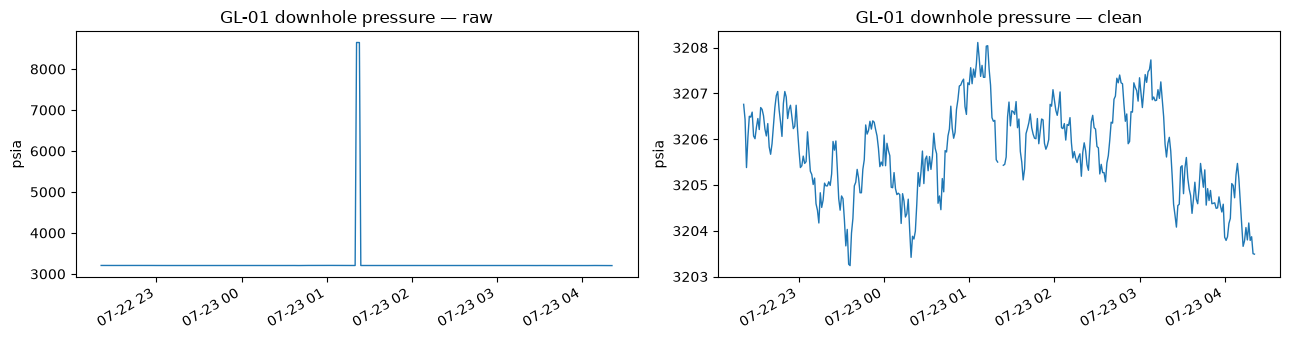

In [5]:
# one example spike: raw vs clean downhole pressure
i = hf_raw.dh_pressure_psia.where(hf_raw.dh_pressure_psia < 9000).idxmax()
well, t = hf_raw.well_name[i], hf_raw.timestamp[i]
window = lambda d: d[(d.well_name == well) & d.timestamp.between(t - pd.Timedelta(hours=3), t + pd.Timedelta(hours=3))]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for a, d, title in [(ax[0], hf_raw, 'raw'), (ax[1], hf, 'clean')]:
    w = window(d)
    a.plot(w.timestamp, w.dh_pressure_psia, lw=1)
    a.set_title(f'{well} downhole pressure — {title}')
    a.set_ylabel('psia')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 3. Features — the physics the model uses

Every well test and every calendar day is summarised from the **same** cleaned minute data
(`features.summarize_minutes`): mean sensors over the test window / the day, fraction of the day on stream.
Then physics features are added (`features.add_physics_features`), e.g.

| Feature | Formula | Why it matters |
|---|---|---|
| drawdown | $P_{res}(t) - P_{wf}$ | inflow: oil rate is proportional to it |
| Darcy productivity index | $J = \dfrac{k\,h}{141.2\,B_o\,\mu_o\,(\ln(r_e/r_w) - 0.75 + s)}$ | how easily the rock delivers oil [STB/d/psi] |
| choke flow term | $S^2\sqrt{WHP - P_{down}}$ | orifice equation: rate ∝ area × √ΔP |
| tubing gradient | $(P_{wf} - WHP)/\text{TVD}$ | density of the fluid column → water cut / gas |
| temperature gap | $T_{res} - T_{dh}$ | more flow keeps the gauge hotter |

In section 4 the k and skin inside J come from **our own build-up analysis**.

In [6]:
base_tests = F.build_test_table(tests_clean, hf)
base_daily = F.build_daily_table(hf)
print('well tests:', base_tests.shape, '  well-days:', base_daily.shape)
print('days fully shut in:', int((base_daily.on_stream_frac == 0).sum()),
      ' days without sensor data (interpolated):', int(base_daily.no_data.sum()))

well tests: (85, 20)   well-days: (2730, 14)
days fully shut in: 5  days without sensor data (interpolated): 1


## 4. Our own permeability and skin — the VFM ↔ PTA bootstrap

Chicken-and-egg: PTA needs the oil rate $q$ before each shut-in (from the VFM, $k = 162.6\,q B\mu/(m h)$), and the
VFM wants $J$, which needs $k$ and skin from PTA. We iterate (`src/own_well_properties.py`):

1. VFM with $J$ **fitted** from the well tests → $q$ before each shut-in
2. Horner analysis of every shut-in with that $q$ → $k$, skin per well
3. Darcy $J$ from $k$, skin → VFM again → new $q$ → PTA again … until $k$ changes < 0.1 %

Wells without any shut-in (4 of 10) keep a $J$ fitted from their tests, pulled 25 % toward the field-typical
Darcy value (`j_source='auto', j_shrink=0.25`).

In [7]:
pvt, completion = pvt_raw.set_index('well_name'), completion_raw.set_index('well_name')
k_skin = None
for round_no in range(5):
    wells = F.build_well_table(pvt_raw, completion_raw, k_skin)
    tt = F.add_physics_features(base_tests, wells)
    dd = F.add_physics_features(base_daily, wells)
    options = {**vfm.FINAL_PHYSICS_OPTIONS, 'j_source': 'fitted' if k_skin is None else 'auto'}
    new = own.build_k_skin(hf, own.physics_daily_oil(tt, dd, options), pvt, completion)
    change = np.nan if k_skin is None else (new.k_md / k_skin.k_md - 1).abs().max() * 100
    print(f'round {round_no}: max k change {change:.3f} %   ' +
          ', '.join(f'{w} k={r.k_md:.1f} s={r.skin:.2f}' for w, r in new.iterrows()))
    converged = k_skin is not None and change < 0.1
    k_skin = new
    if converged:
        break

saved = load.load_own_k_skin()
print('\nmax difference to data/processed/own_pta_k_skin.csv (used by the app):',
      float((k_skin.k_md - saved.k_md).abs().max()), 'md')
wells = F.build_well_table(pvt_raw, completion_raw, k_skin)
tests = F.add_physics_features(base_tests, wells)
daily = F.add_physics_features(base_daily, wells)
wells[['well_name', 'J_from_pta', 'k_md', 'skin', 'J_darcy', 'solution_gor_at_pb_scf_stb']].round(3)

round 0: max k change nan %   GL-01 k=105.9 s=5.83, GL-02 k=58.9 s=-0.56, GL-04 k=54.4 s=-1.25, GL-06 k=297.6 s=2.00, GL-08 k=42.8 s=-1.62, GL-10 k=192.5 s=2.05


round 1: max k change 8.742 %   GL-01 k=106.3 s=5.83, GL-02 k=56.0 s=-0.53, GL-04 k=54.4 s=-1.25, GL-06 k=295.0 s=2.01, GL-08 k=42.8 s=-1.62, GL-10 k=175.7 s=2.09


round 2: max k change 0.897 %   GL-01 k=106.3 s=5.83, GL-02 k=56.2 s=-0.54, GL-04 k=54.4 s=-1.25, GL-06 k=295.2 s=2.00, GL-08 k=42.8 s=-1.62, GL-10 k=177.2 s=2.09


round 3: max k change 0.083 %   GL-01 k=106.3 s=5.83, GL-02 k=56.2 s=-0.53, GL-04 k=54.4 s=-1.25, GL-06 k=295.2 s=2.00, GL-08 k=42.8 s=-1.62, GL-10 k=177.1 s=2.09

max difference to data/processed/own_pta_k_skin.csv (used by the app): 0.0 md


,well_name,J_from_pta,k_md,skin,J_darcy,solution_gor_at_pb_scf_stb
0,GL-01,True,106.297,5.826,3.701,277.8
1,GL-02,True,56.220,-0.535,3.800,301.4
2,GL-03,False,81.259,0.735,1.513,222.0
3,GL-04,True,54.395,-1.255,0.865,237.5
4,GL-05,False,81.259,0.735,2.226,325.7
5,GL-06,True,295.150,2.005,5.450,217.0
6,GL-07,False,81.259,0.735,4.747,268.3
7,GL-08,True,42.835,-1.617,2.584,336.2
8,GL-09,False,81.259,0.735,2.078,160.0
9,GL-10,True,177.102,2.087,7.428,230.0


## 5. Final VFM model

| Fluid | Model |
|---|---|
| **Oil** | $q_o = J\,(P_{res}(t) - P_{wf})$. $P_{wf}$ = downhole gauge (measured every minute). $P_{res}(t)$ per well = **local linear trend** of the reservoir pressure implied by the tests ($P_{wf} + q_o/J$), Gaussian time weights (bandwidth 90 days) → follows depletion that accelerates or slows. |
| **Gas** | $q_g = q_o \cdot R_s / 1000$ — formation gas from the **solution GOR** in the completion file (the reservoir is above the bubble point, so the produced GOR equals $R_s$; lift gas is excluded). |
| **Water** | ½ physics $q_o \cdot WC/(100-WC)$ with $WC(t)$ linear in time (recent tests weighted, τ = 120 d) + ½ **Gaussian process** on *separator-safe* inputs (downhole P & T, annulus P, lift gas, time, J). |
| **Daily rate** | flowing rate × fraction of the day on stream; fully shut-in day = 0. |

Why so much physics? 85 labels only. Pure ML (LightGBM, XGBoost …) on 85 points loses even to "repeat the last
test" (section 6); physics needs only 2–3 numbers per well and extrapolates in time.

In [8]:
model = vfm.train_final_model(tests)
with open(load.ROOT / 'models' / 'vfm_model.pkl', 'wb') as fh:      # .pkl = required deliverable format
    pickle.dump(model, fh)
joblib.dump(model, load.ROOT / 'models' / 'vfm_model.joblib')

rates = vfm.predict_rates(model, daily)
predictions = export.vfm_table(daily, rates)
print('model:', model['name'])
print('physics options:', vfm.FINAL_PHYSICS_OPTIONS)
print('predictions:', predictions.shape)

best = pd.read_csv(OUT / 'submission' / 'vfm_submission_v5.csv')
mine = export.vfm_submission(predictions)
diff = (mine[V.TARGETS].values - best[V.TARGETS].values)
print('max |difference| to the best benchmark submission v5 (21.089 / 30):', np.abs(diff).max())
predictions.head()

model: Final VFM (v5): physics + Gaussian process (water)
physics options: {'recency_tau': 120, 'gor_model': 'rs', 'pres_local_bw': 90, 'j_source': 'auto', 'j_shrink': 0.25}
predictions: (2730, 5)
max |difference| to the best benchmark submission v5 (21.089 / 30): 0.0


,date,well_name,oil_rate_stbd,water_rate_stbd,gas_rate_mscfd
0,2025-01-01,GL-01,1149.98,791.39,319.46
1,2025-01-02,GL-01,1151.20,791.75,319.80
2,2025-01-03,GL-01,1174.24,801.66,326.20
3,2025-01-04,GL-01,1167.10,798.49,324.22
4,2025-01-05,GL-01,1153.84,793.62,320.54


## 6. VFM validation

Official metrics per fluid: $R^2$, MAPE and **WAPE** $=\sum|pred-true| / \sum|true|$ (volume-weighted — high-rate
wells dominate). Two questions:

* **Between tests** (leave-one-test-out, LOTO): hide one test, train on the other 84, predict it.
* **Forecasting** (time-forward): train only on tests before 1 Jun (and 1 Jul), predict the next 92 days.
  This is what the judges' test data (after September) asks for — and it is harder.

### 6.1 How each modelling step earns its place

In [9]:
P = vfm.make_physics_method
steps = {
    '0 naive: repeat last test': vfm.time_interpolation,
    '1 physics: J (own PTA) x drawdown, linear P_res, WC, GOR trends': P(j_source='auto', j_shrink=0.25),
    '2 + recent tests weighted (tau 120 d)': P(j_source='auto', j_shrink=0.25, recency_tau=120),
    '3 + gas = oil x Rs': P(j_source='auto', j_shrink=0.25, recency_tau=120, gor_model='rs'),
    '4 + local P_res trend (90 d)': P(**vfm.FINAL_PHYSICS_OPTIONS),
    '5 + Gaussian process for water = FINAL': vfm.final_method(),
}
rows, loto_preds, fwd_preds = [], {}, {}
for name, method in steps.items():
    loto_preds[name] = V.leave_one_test_out(tests, method)
    fwd_preds[name] = V.time_forward(tests, method)
    row = {'step': name}
    for kind, true, pred in [('between', tests, loto_preds[name]),
                             ('forecast', tests.loc[fwd_preds[name].test_index], fwd_preds[name])]:
        for t in V.TARGETS:
            m = V.official_metrics(true[t].values, pred[t].values)
            row[f'{kind} {t.split("_")[0]} WAPE'] = m['WAPE']
    rows.append(row)
progress = pd.DataFrame(rows).set_index('step')
progress.round(2)

,between oil WAPE,between water WAPE,between gas WAPE,forecast oil WAPE,forecast water WAPE,forecast gas WAPE
step,,,,,,
0 naive: repeat last test,3.14,4.03,5.61,8.16,5.32,10.22
"1 physics: J (own PTA) x drawdown, linear P_res, WC, GOR trends",2.08,3.39,4.33,4.12,5.53,5.39
2 + recent tests weighted (tau 120 d),2.16,3.50,4.32,3.69,5.71,4.95
3 + gas = oil x Rs,2.16,3.50,4.40,3.69,5.71,6.00
4 + local P_res trend (90 d),2.03,3.38,4.33,3.52,5.55,5.63
5 + Gaussian process for water = FINAL,2.03,3.08,4.33,3.52,4.92,5.63


Reading the table:
* Physics beats the naive forecast by a wide margin, both between tests and forward in time.
* Recency weighting and the local $P_{res}$ trend help mainly **forecasting** (depletion is not perfectly linear).
* **Gas = oil × Rs looks slightly worse against the test labels** — because the measured test GOR is *noisy*
  (separator measurement), while $R_s$ is the clean physical constant. On the organisers' benchmark (scored against
  the noise-free truth) it was a clear gain (20.975 → 21.183 / 30). Lesson: where the data provider gives a clean
  physical constant, use it rather than a noisy average.
* The Gaussian process adds information to water (paired Wilcoxon test p < 0.001 in the model-zoo study).

In [10]:
final = vfm.final_method()
loto, forward = loto_preds['5 + Gaussian process for water = FINAL'], fwd_preds['5 + Gaussian process for water = FINAL']
metrics = {'model': model['name'], 'physics_options': vfm.FINAL_PHYSICS_OPTIONS, 'n_tests': len(tests)}
table = {}
for kind, true, pred in [('loto', tests, loto), ('forward', tests.loc[forward.test_index], forward)]:
    for t in V.TARGETS:
        m = V.official_metrics(true[t].values, pred[t].values)
        table[(kind, t.split('_')[0])] = m
        for name, value in m.items():
            metrics[f'{kind}_{t.split("_")[0]}_{name}'] = round(float(value), 4)
with open(OUT / 'final_model_metrics.json', 'w') as fh:
    json.dump(metrics, fh, indent=1)
final_metrics = pd.DataFrame(table).T.round(3)
final_metrics.index = final_metrics.index.set_names(['validation', 'fluid'])
final_metrics

R2   MAPE   WAPE
validation fluid                     
loto       oil    0.999  2.392  2.029
           water  0.997  3.424  3.081
           gas    0.995  5.498  4.328
forward    oil    0.996  4.279  3.521
           water  0.988  4.547  4.917
           gas    0.993  8.034  5.630

In [11]:
per_well = V.score_per_well(tests, loto).add_suffix(' MAPE % (between tests)').round(2)
per_well

,oil_rate_stbd MAPE % (between tests),water_rate_stbd MAPE % (between tests),gas_rate_mscfd MAPE % (between tests)
well_name,,,
GL-01,2.73,3.32,4.24
GL-02,1.37,3.51,2.82
GL-03,3.49,2.78,5.33
GL-04,1.55,3.73,8.77
GL-05,3.31,5.30,7.85
GL-06,3.07,2.53,8.65
GL-07,1.26,1.72,3.02
GL-08,2.68,4.24,3.10
GL-09,2.69,3.07,6.66


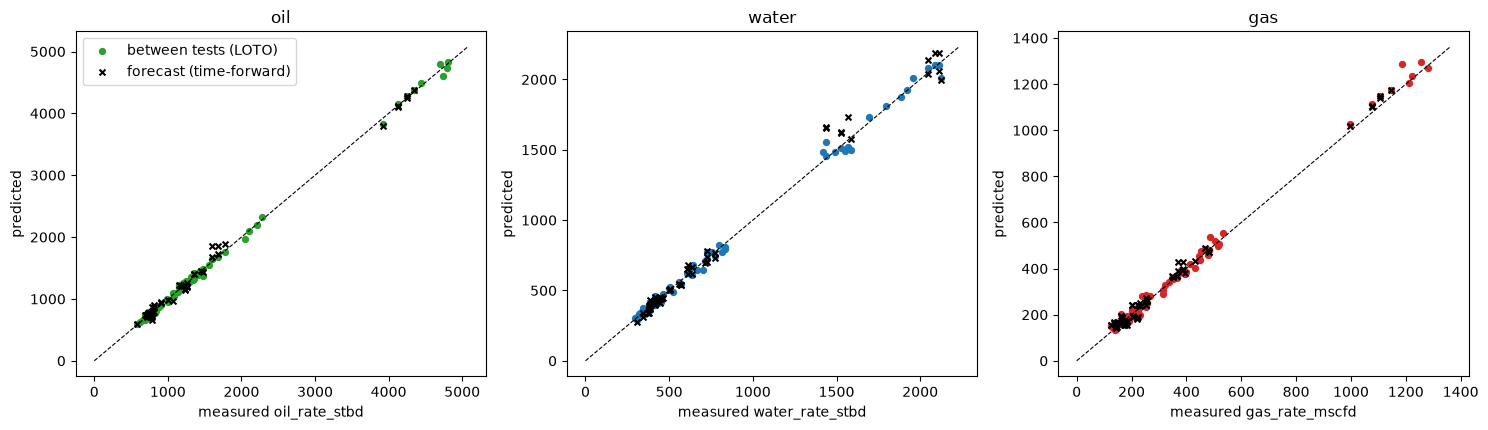

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, t, color in zip(axes, V.TARGETS, ['tab:green', 'tab:blue', 'tab:red']):
    ax.scatter(tests[t], loto[t], s=18, color=color, label='between tests (LOTO)')
    ax.scatter(tests.loc[forward.test_index, t], forward[t], s=18, marker='x', color='k', label='forecast (time-forward)')
    lim = [0, max(tests[t].max(), loto[t].max()) * 1.05]
    ax.plot(lim, lim, 'k--', lw=0.8)
    ax.set_xlabel(f'measured {t}')
    ax.set_ylabel('predicted')
    ax.set_title(t.split('_')[0])
axes[0].legend()
plt.tight_layout()
plt.show()

### 6.2 The test-separator effect — a blind spot of validating only on well tests

During a well test the flow goes to the **test separator**, which runs at lower pressure → flowline pressure is
17–29 psi lower than on a normal day, and the well produces slightly more. **Every label is a test**, so LOTO and
time-forward cannot see this — but the deliverable predicts **normal days**. An ML model given flowline/choke inputs
learns the test-only regime and over-predicts normal days. Physics is immune (it uses $P_{wf}$, which the gauge
measures on every day). Check below: model ÷ physics on all normal (fully on-stream) days.

In [13]:
normal = daily[(daily.on_stream_frac == 1) & daily.dh_pressure_psia.notna()]
cols = ['whp_downstream_psia', 'whp_psia', 'dh_pressure_psia']
print('Mean during TESTS minus mean on NORMAL days (psi):')
print((tests.groupby('well_name')[cols].mean() - normal.groupby('well_name')[cols].mean()).round(1).T)

well_ids = sorted(tests.well_name.unique())
phys = vfm.physics_predict(normal, vfm.fit_well_trends(tests, **vfm.FINAL_PHYSICS_OPTIONS))
rows = []
for name, feats in [('GP on all physics features', vfm.PHYSICS_FEATURES),
                    ('GP on separator-safe features (used)', vfm.SEPARATOR_SAFE_FEATURES)]:
    for t in ['oil_rate_stbd', 'water_rate_stbd']:
        gp = vfm.gaussian_process().fit(vfm.design_matrix(tests, feats, well_ids), tests[t])
        ratio = gp.predict(vfm.design_matrix(normal, feats, well_ids)) / phys[t]
        rows.append({'model': name, 'target': t, 'median model/physics on normal days': np.median(ratio)})
pd.DataFrame(rows).round(3)

Mean during TESTS minus mean on NORMAL days (psi):
well_name            GL-01  GL-02  GL-03  GL-04  GL-05  GL-06  GL-07  GL-08  GL-09  GL-10
whp_downstream_psia  -26.6  -28.0  -28.0  -28.7  -28.3  -19.1  -17.5  -18.3  -18.8  -19.0
whp_psia             -13.6  -18.4  -15.0  -13.3  -20.1   -0.6  -10.8   -9.8   -4.0   -9.3
dh_pressure_psia      -9.0  -14.4  -17.9  -18.1  -30.9   -0.6   -6.7   -8.6   -3.3   -4.9


,model,target,median model/physics on normal days
0,GP on all physics features,oil_rate_stbd,1.094
1,GP on all physics features,water_rate_stbd,1.017
2,GP on separator-safe features (used),oil_rate_stbd,1.008
3,GP on separator-safe features (used),water_rate_stbd,1.017


### 6.3 Model comparison (47 experiments)

Full ablation (`notebooks/16_full_evaluation.ipynb`, run at an earlier stage with the same validation): naive
baselines, pure ML on raw / physics features (A), physics (B), hybrids (C), synthetic pre-training (D) and
ensembles (E/F). Ranked by forecast WAPE; `normal_bias` = mean deviation from physics on normal days
(test-separator check). Smooth models (Gaussian process, Ridge) beat trees on 85 points; nothing beats physics for
oil and gas, and models using flowline features are biased on normal days.

In [14]:
ev = pd.read_csv(OUT / 'full_evaluation_results.csv')
show = ['experiment', 'loto_mean_WAPE', 'fwd_mean_WAPE', 'fwd_oil_WAPE', 'fwd_water_WAPE', 'fwd_gas_WAPE',
        'normal_bias_oil_pct', 'normal_bias_water_pct']
print(len(ev), 'experiments')
ev[show].sort_values('fwd_mean_WAPE').round(2).reset_index(drop=True)

47 experiments


,experiment,loto_mean_WAPE,fwd_mean_WAPE,fwd_oil_WAPE,fwd_water_WAPE,fwd_gas_WAPE,normal_bias_oil_pct,normal_bias_water_pct
0,C3 eng-targets Ridge + label feats OOF,3.22,4.41,3.17,4.15,5.91,-3.38,-16.67
1,F2 rec120 + GP-safe water (current final),3.12,4.49,3.63,4.95,4.88,0.00,0.82
2,F1 rec120 + GP-all oil&water,3.07,4.54,3.46,5.27,4.88,5.20,1.87
3,rec120 + GP-safe oil&water,3.06,4.58,3.90,4.95,4.88,0.40,0.82
4,E3 physics + GP-all oil&water,3.07,4.65,3.53,5.14,5.29,5.34,2.07
5,B physics rec60,3.57,4.69,3.44,5.99,4.66,0.05,0.02
6,B physics rec120,3.27,4.74,3.63,5.69,4.88,0.00,0.00
7,B physics rec120 + WC tubing,3.29,4.77,3.63,5.80,4.88,0.00,-0.06
8,E2 physics + GP-all water,3.06,4.82,4.02,5.14,5.29,0.00,2.07
9,D ExtraTrees synthetic_only,4.22,4.87,3.85,5.15,5.60,0.18,-0.02


### 6.4 Official benchmark (organisers' scoring page, /30 for VFM)

| Version | Change | Score |
|---|---|---|
| v1 | physics + GP water | 20.975 |
| v2 | gas = oil × Rs | 21.183 |
| v3 | water cut from BSW instead of metered WC | 21.118 (rejected) |
| v4 | local P_res trend (90 d) | 21.224 |
| **v5 (final)** | J from **our own** build-up k & skin — the pipeline is fully self-contained | **21.089** |

v5 is the final model: every input to it comes from the provided raw data and our own analysis.
Rule we followed: a change is kept only if it does not hurt time-forward validation **and** passes the normal-day
check; the benchmark was used to test hypotheses about the physics, not to tune knobs.

## 7. VFM deliverables
* `outputs/VFM_predictions.xlsx` — sheet `predictions` = required columns (`date, well_name, oil_rate_stbd,
  water_rate_stbd, gas_rate_mscfd`), plus `model_info`, `validation`, `daily_details`
* `outputs/VFM_predictions.csv` — same table in the organisers' template format
* `models/vfm_model.pkl` — the trained model (written in section 5)
* `outputs/plots/vfm_<well>.png` — daily rates vs measured tests

In [15]:
flowing = daily[daily.dh_pressure_psia.notna()]
phys_daily = vfm.physics_predict(flowing, model['trends']).reindex(daily.index)
details = pd.DataFrame({
    'date': daily.date.dt.date, 'well_name': daily.well_name,
    'on_stream_frac': daily.on_stream_frac.round(3),
    'no_sensor_data_interpolated': daily.no_data,
    'reservoir_pressure_psia_at_gauge': phys_daily.P_res.round(1),
    'downhole_pressure_psia': daily.dh_pressure_psia.round(1),
    'choke_opening_pct': daily.choke_opening_pct.round(1),
})
model_info = [
    ('model', 'Final VFM: physics + Gaussian-process hybrid (benchmark submission v5, 21.089 / 30)'),
    ('oil', 'q_oil = J * (P_res(t) - Pwf); J from Darcy with our own build-up k & skin (6 wells) or fitted from tests '
            '(4 wells without a shut-in, 25 % toward prior); P_res(t) local linear trend per well (Gaussian time weights, 90 d)'),
    ('gas', 'q_gas = q_oil * Rs / 1000; Rs = solution GOR from the completion file (formation gas, excludes lift gas)'),
    ('water', '0.5 * physics (q_oil * WC(t)/(100-WC(t)), WC linear in time, tau 120 d) + 0.5 * Gaussian process on separator-safe inputs'),
    ('daily rate', 'flowing rate * fraction of the day on stream; fully shut-in day = 0'),
    ('training data', '85 well tests, cleaned (5 sign flips, GL-06 gas Sm3/d -> Mscf/d)'),
    ('LOTO WAPE oil / water / gas %', f"{metrics['loto_oil_WAPE']:.2f} / {metrics['loto_water_WAPE']:.2f} / {metrics['loto_gas_WAPE']:.2f}"),
    ('forecast WAPE oil / water / gas %', f"{metrics['forward_oil_WAPE']:.2f} / {metrics['forward_water_WAPE']:.2f} / {metrics['forward_gas_WAPE']:.2f}"),
    ('units', 'oil, water: STB/d; gas: Mscf/d'),
]
validation_sheet = pd.concat([V.score(tests, loto).round(3), per_well])
export.write_vfm_excel(OUT / 'VFM_predictions.xlsx', predictions, model_info, validation_sheet, details)
export.write_submission(export.vfm_submission(predictions), OUT / 'VFM_predictions.csv')
print('written: outputs/VFM_predictions.xlsx, outputs/VFM_predictions.csv')

written: outputs/VFM_predictions.xlsx, outputs/VFM_predictions.csv


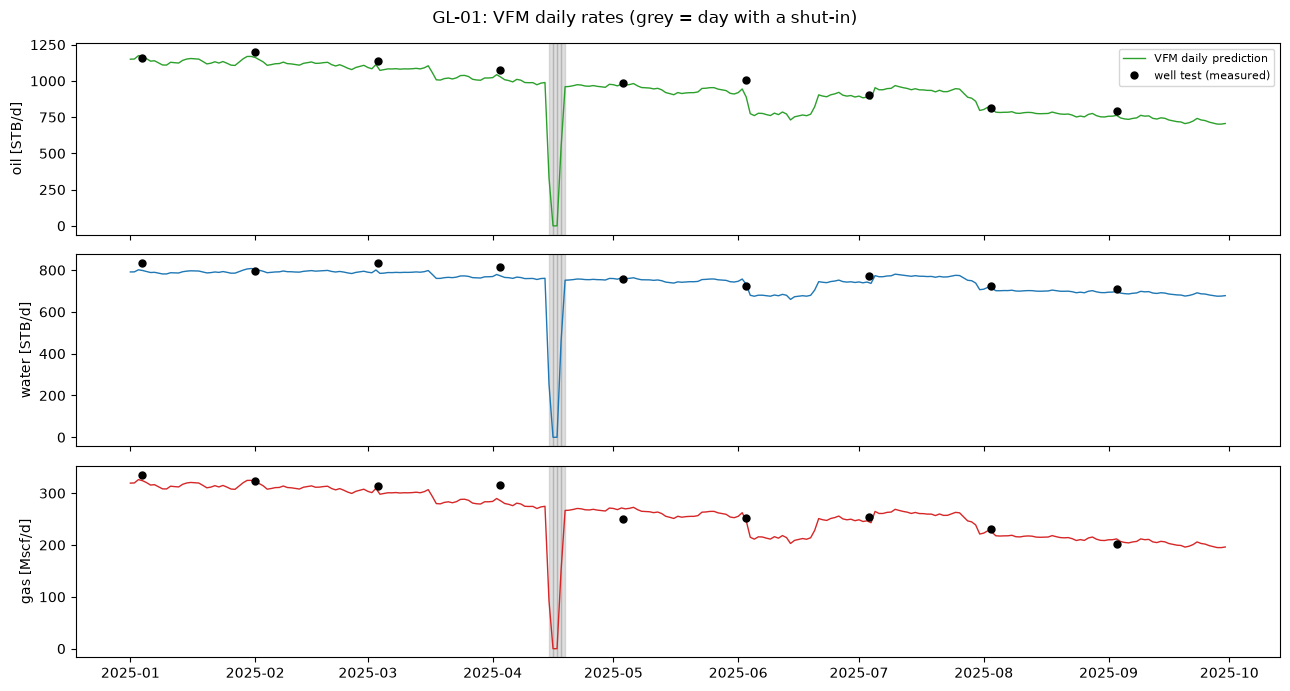

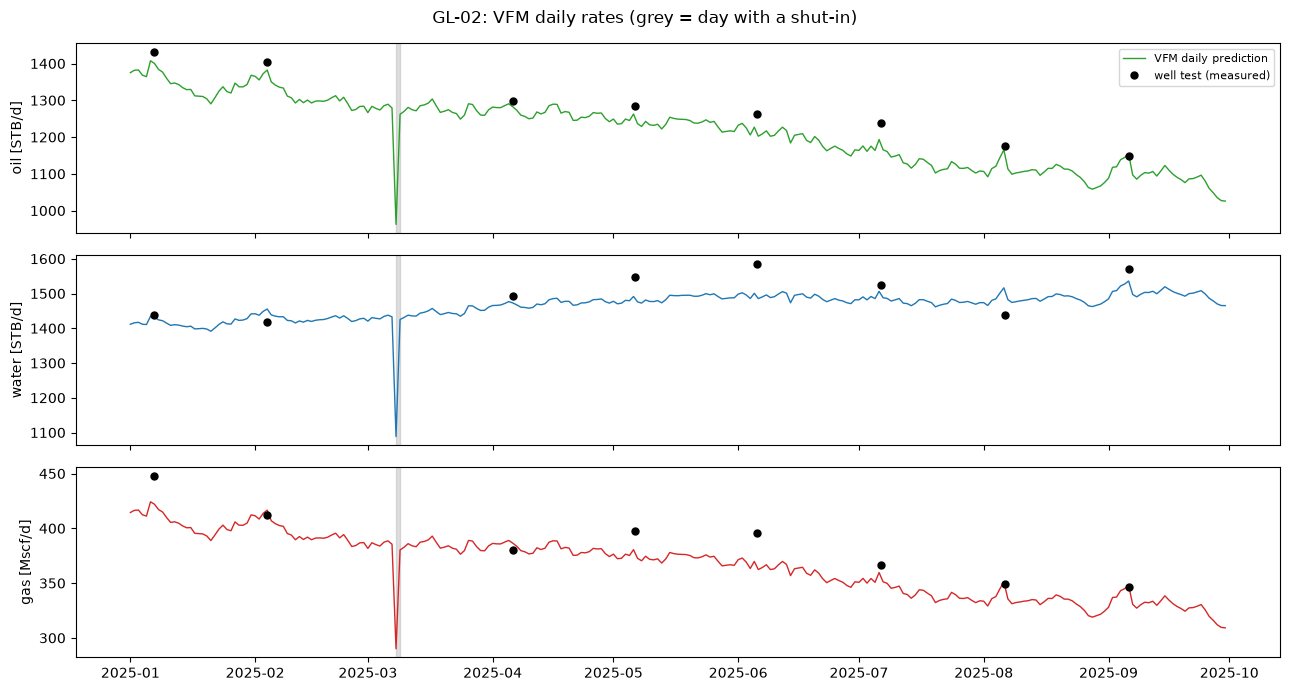

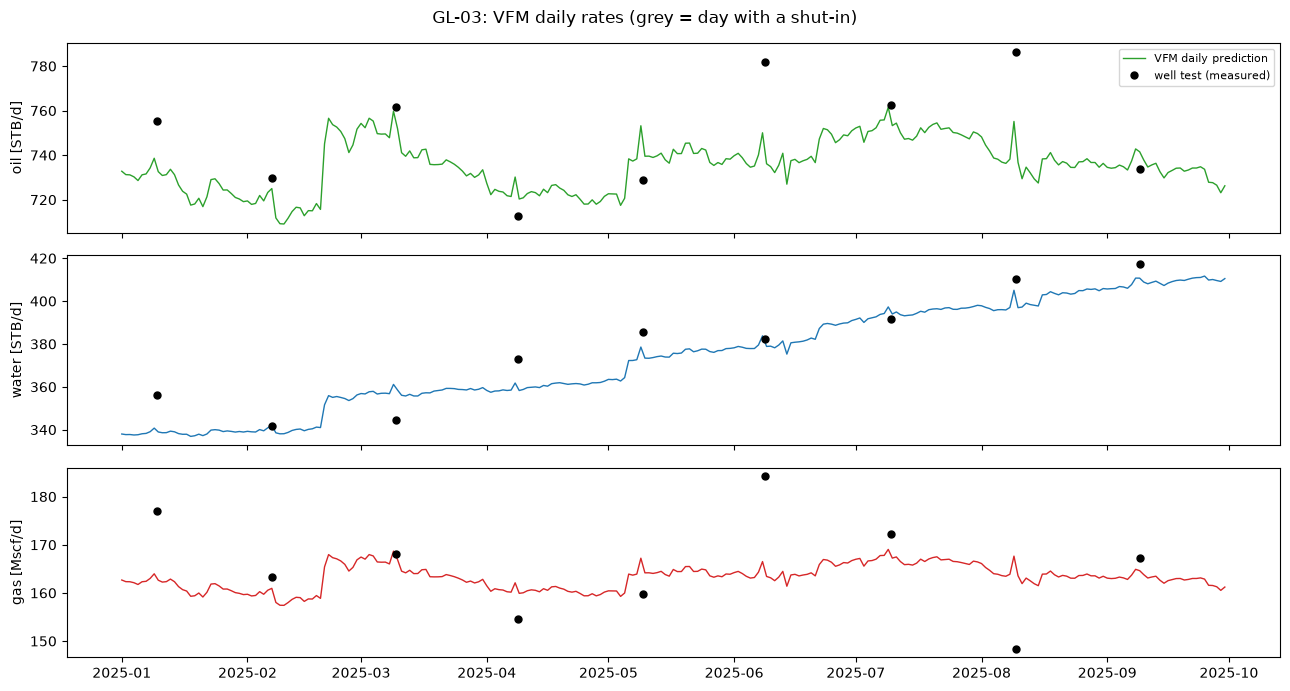

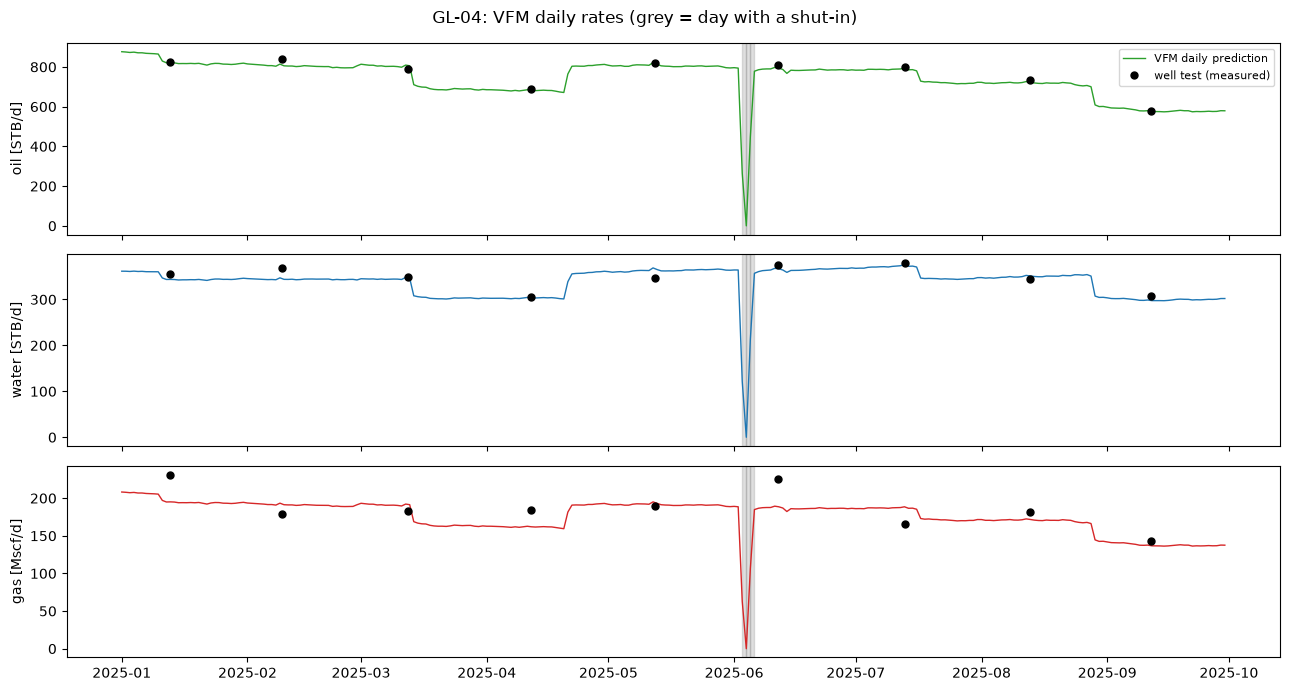

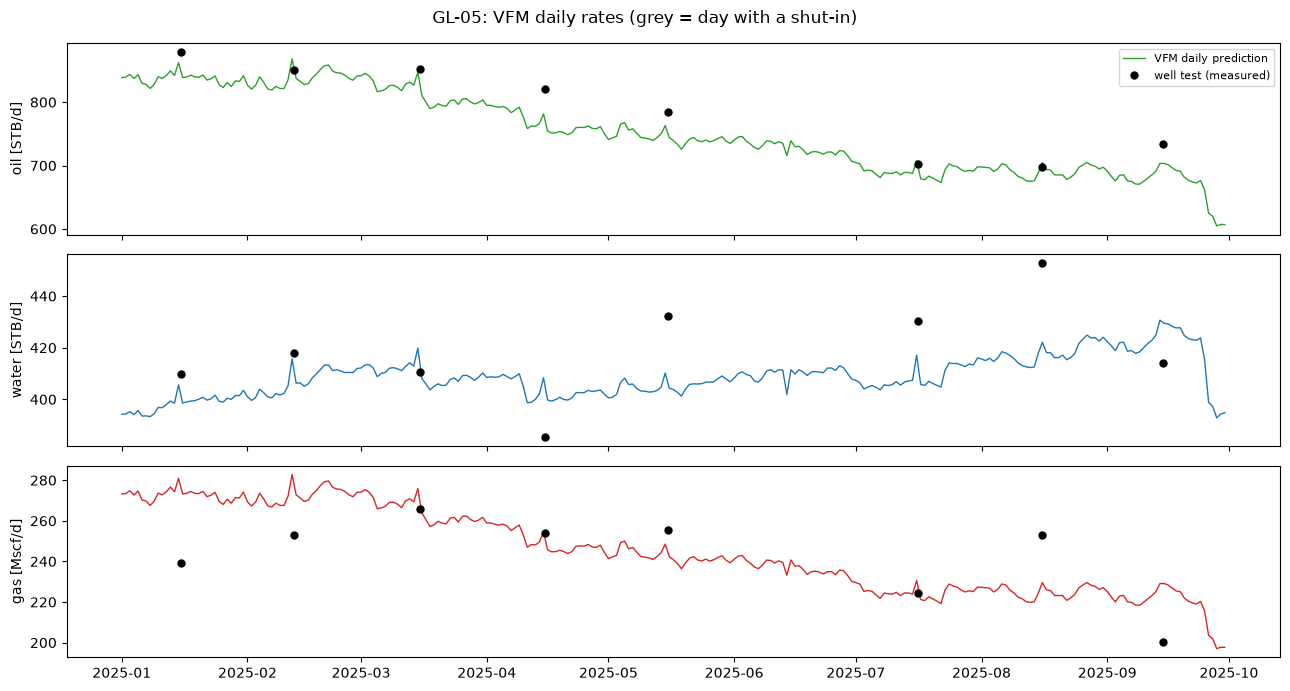

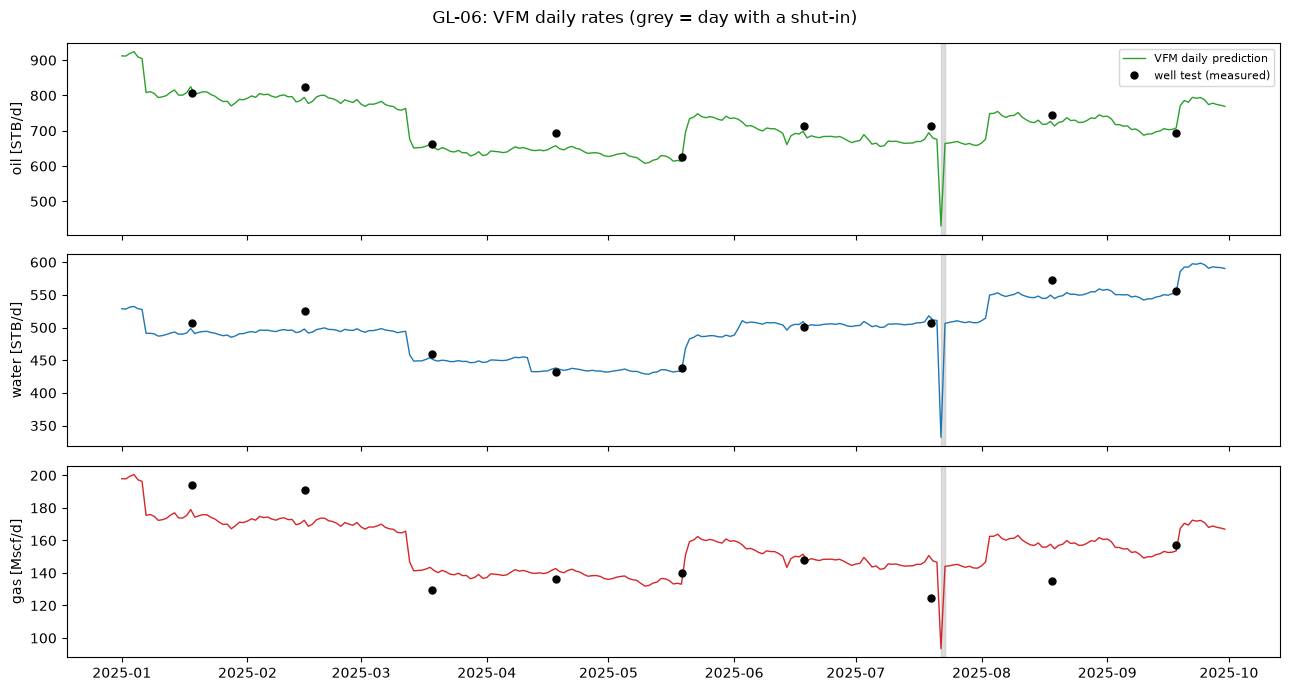

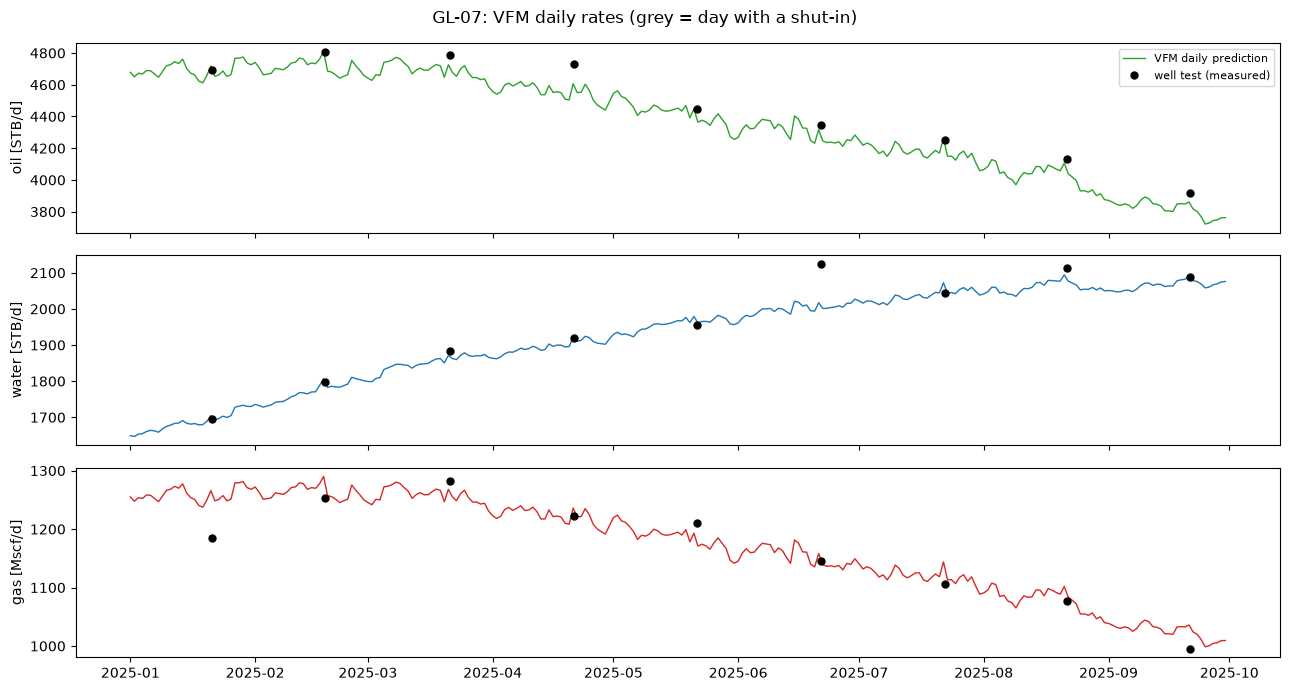

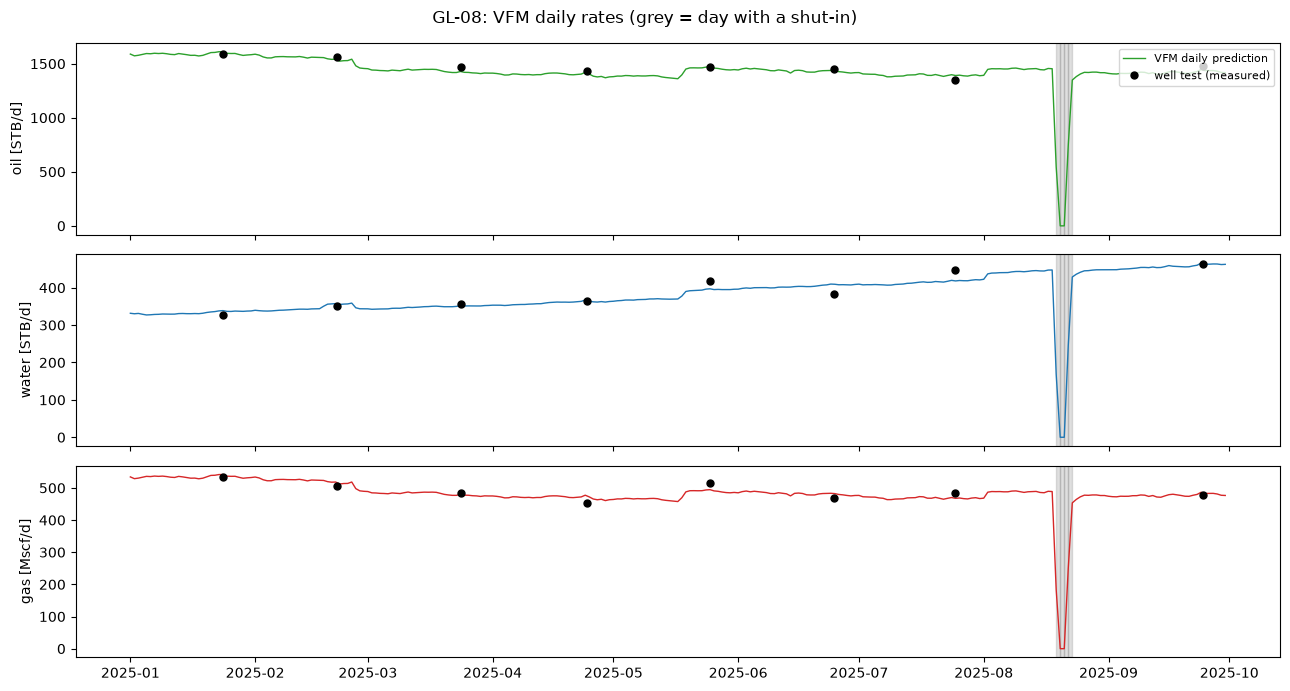

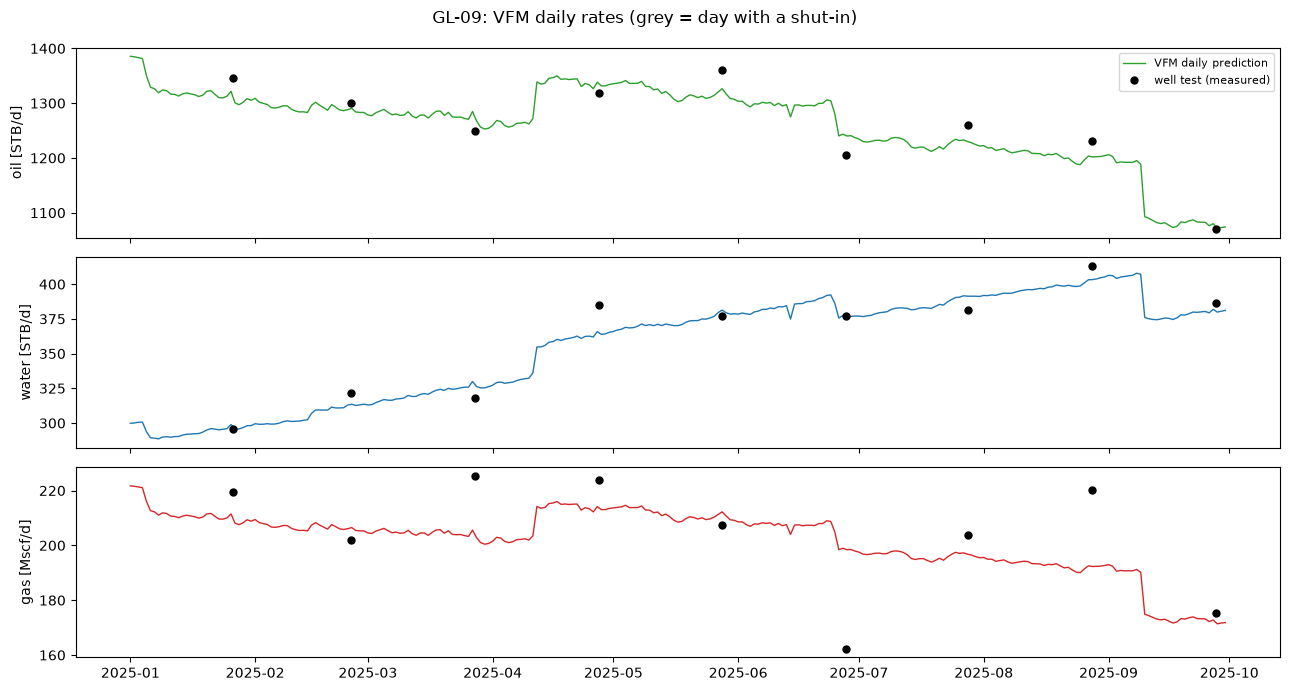

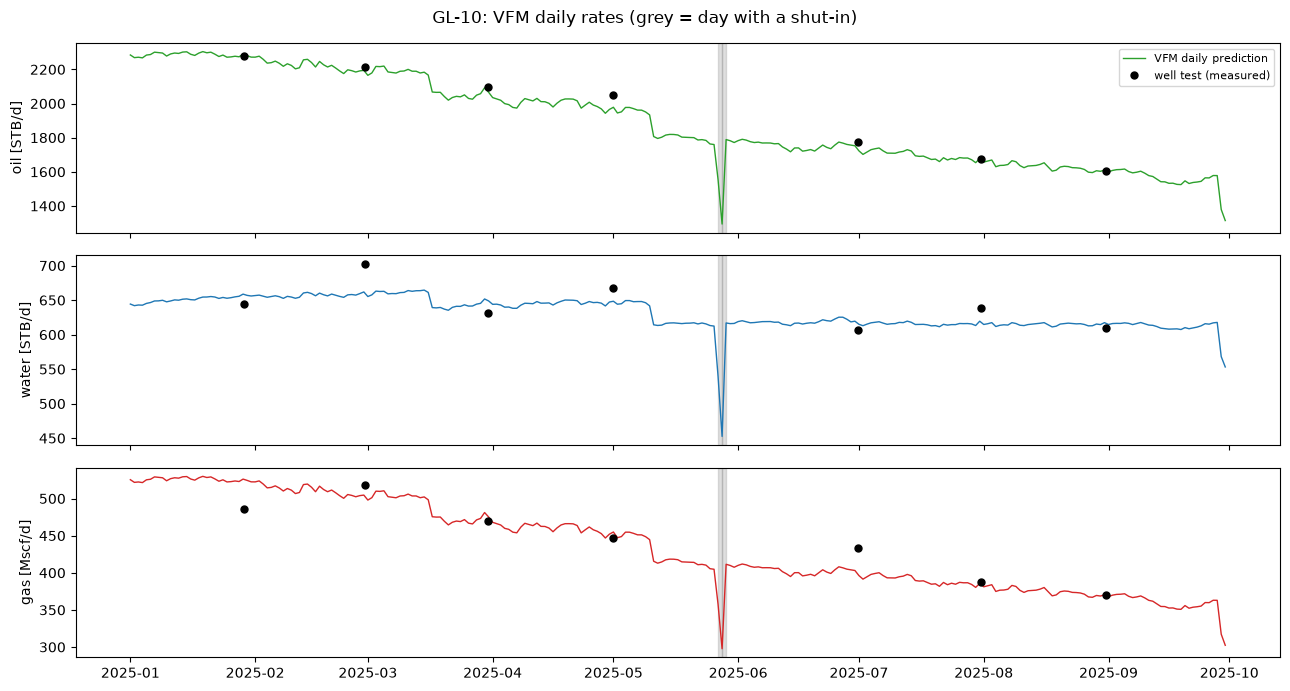

In [16]:
def plot_vfm_well(well):
    d = predictions[predictions.well_name == well]
    t = tests[tests.well_name == well]
    shut = daily[(daily.well_name == well) & (daily.on_stream_frac < 1)].date
    fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
    for ax, col, color, unit in zip(axes, V.TARGETS, ['tab:green', 'tab:blue', 'tab:red'], ['STB/d', 'STB/d', 'Mscf/d']):
        ax.plot(pd.to_datetime(d.date), d[col], color=color, lw=1, label='VFM daily prediction')
        ax.plot(t.time, t[col], 'ko', ms=5, label='well test (measured)')
        for day in shut:
            ax.axvspan(day, day + pd.Timedelta(days=1), color='grey', alpha=0.25)
        ax.set_ylabel(f'{col.split("_")[0]} [{unit}]')
    axes[0].legend(loc='upper right', fontsize=8)
    fig.suptitle(f'{well}: VFM daily rates (grey = day with a shut-in)')
    fig.tight_layout()
    fig.savefig(OUT / 'plots' / f'vfm_{well}.png', dpi=110)
    plt.show()

for well in sorted(daily.well_name.unique()):
    plot_vfm_well(well)

## 8. Automatic pressure transient analysis (build-up tests)

**Detection:** a shut-in = choke opening 0 % (per-minute downhole pressure then builds up).

**Classification** (textbook: Earlougher; Horne — a build-up *test* is a planned operation: stabilised rate,
long enough shut-in, controlled restart): **planned build-up test** = duration ≥ 24 h **and** a staged choke ramp-up
(≥ 2 steps) on reopening. Otherwise it is an **unplanned shut-in** (trip): analysed and shown, but not reported.

**Horner analysis** (field units), for each test:

| Step | Formula |
|---|---|
| rate before shut-in | $q$ = mean VFM oil rate of the 7 days before |
| flowing pressure | $P_{wf}(\Delta t{=}0)$ = mean downhole pressure of the 24 h before |
| producing time | $t_p = 24\,N_p/q$ [h], $N_p$ = cum oil at 1 Jan 2025 + VFM oil since |
| radial-flow window | flattest **Bourdet derivative** $dP/d\ln\Delta t_e$ (Agarwal equivalent time) after the storage hump |
| Horner line | $P_{ws} = P^* - m\,\log_{10}\frac{t_p+\Delta t}{\Delta t}$ (least squares on the window) |
| permeability | $k = 162.6\,q B_o \mu_o / (m h)$ [md] |
| skin | $s = 1.151\left[\frac{P_{1hr} - P_{wf}}{m} - \log_{10}\frac{k}{\phi\mu c_t r_w^2} + 3.23\right]$ |
| ΔP skin | $\Delta P_{skin} = 0.869\,m\,s$ [psi] |
| flow efficiency | $FE = (P^* - P_{wf} - \Delta P_{skin})/(P^* - P_{wf})$ |

**Cross-check — analytical model matching** (`src/pta_model.py`): Laplace-space solution with wellbore storage +
skin + {infinite, constant-pressure circle, closed circle}, Stehfest inversion, least squares on log ΔP; a boundary
is accepted only if AIC improves by > 4 and it lies inside the radius of investigation.

In [17]:
vfm_daily = predictions.assign(date=pd.to_datetime(predictions.date))
rates_for_pta = vfm_daily.rename(columns={'oil_rate_stbd': 'oil'})[['date', 'well_name', 'oil']]
events = pta.find_shut_ins(hf)
results = pta.analyze_all(hf, events, rates_for_pta, pvt, completion, choke)
pd.DataFrame([{k: r[k] for k in ['well_name', 't_shut', 'duration_hr', 'restart_steps', 'event_type',
                                 'classification_reason']} for r in results])

,well_name,t_shut,duration_hr,restart_steps,event_type,classification_reason
0,GL-01,2025-04-15 08:00:00,72.00,3,planned build-up test,72.0 h (>= 24 h); reopened in 3 choke step(s) ...
1,GL-02,2025-03-08 14:23:00,5.65,1,unplanned shut-in,5.7 h (< 24 h); reopened in 1 choke step(s) (o...
2,GL-04,2025-06-03 08:00:00,48.00,3,planned build-up test,48.0 h (>= 24 h); reopened in 3 choke step(s) ...
3,GL-06,2025-07-22 03:11:00,8.00,1,unplanned shut-in,8.0 h (< 24 h); reopened in 1 choke step(s) (o...
4,GL-08,2025-08-19 09:00:00,72.00,3,planned build-up test,72.0 h (>= 24 h); reopened in 3 choke step(s) ...
5,GL-10,2025-05-27 21:04:00,9.00,1,unplanned shut-in,9.0 h (< 24 h); reopened in 1 choke step(s) (o...


In [18]:
rows, sens_all, fits_all = [], [], {}
for r in results:
    p = pvt.loc[r['well_name']]
    fits, best_fit, dt_fit, dp_fit = pta_model.fit_all_models(r, p)
    fits_all[(r['well_name'], r['t_shut'])] = (fits, best_fit, dt_fit, dp_fit)
    event = {'well_name': r['well_name'], 't_shut': r['t_shut'], 't_open': r['t_open'], 'duration_hr': r['duration_hr']}
    sens = pta.sensitivity(hf, event, r['q_oil_stbd'], r['cum_oil_stb'], p)
    sens_all.append(sens)
    method_cases = sens[~sens.case.str.startswith('q ')]
    row = {k: v for k, v in r.items() if not k.startswith('_')}
    row.update({
        'model_boundary': best_fit['boundary'], 'model_k_md': best_fit['k_md'], 'model_skin': best_fit['skin'],
        'model_C_bbl_psi': best_fit['C_bbl_psi'], 'model_boundary_radius_ft': best_fit['boundary_radius_ft'],
        'model_fit_rms_pct': best_fit['rms_error_pct'],
        'k_uncertainty_analysis_pct': method_cases.k_change_pct.abs().max(),
        'skin_uncertainty_analysis': method_cases.skin_change.abs().max(),
        'interpretation': pta.interpret(r['k_md'], r['skin'], r['dP_skin_psi'], r['flow_efficiency'], best_fit['boundary'],
                                        best_fit['boundary_radius_ft'], best_fit['radius_investigation_ft']),
    })
    rows.append(row)
pta_details = pd.DataFrame(rows)
for _, r in pta_details.iterrows():
    print(f"{r.well_name} {r.t_shut:%Y-%m-%d} [{r.event_type}]: {r.interpretation}")

GL-01 2025-04-15 [planned build-up test]: high permeability (106 md); DAMAGED (skin 5.8, 116 psi lost, flow efficiency 0.68) -> stimulation candidate; pressure support (constant-pressure boundary) at ~727 ft
GL-02 2025-03-08 [unplanned shut-in]: moderate permeability (56 md); stimulated well (skin -0.5, flow efficiency 1.04); no boundary seen within ~350 ft (infinite-acting)
GL-04 2025-06-03 [planned build-up test]: moderate permeability (55 md); stimulated well (skin -1.3, flow efficiency 1.12); no boundary seen within ~913 ft (infinite-acting)
GL-06 2025-07-22 [unplanned shut-in]: high permeability (295 md); mildly damaged (skin 2.0, 27 psi lost to skin); no boundary seen within ~575 ft (infinite-acting)
GL-08 2025-08-19 [planned build-up test]: moderate permeability (43 md); stimulated well (skin -1.6, flow efficiency 1.16); no boundary seen within ~1098 ft (infinite-acting)
GL-10 2025-05-27 [unplanned shut-in]: high permeability (179 md); mildly damaged (skin 2.0, 49 psi lost to sk

### 8.1 PTA results — planned build-up tests (the deliverable)

In [19]:
planned = pta_details[pta_details.event_type == 'planned build-up test']
pta_results_table = export.pta_table(planned)
best_pta = pd.read_csv(OUT / 'submission' / 'pta_probe_v8d_long_only.csv')
mine = export.pta_submission(pta_results_table)
cols = ['permeability_md', 'skin', 'delta_p_skin_psi', 'horner_slope']
print('max |difference| to the best benchmark PTA submission (12.70 / 20):',
      float(np.abs(mine[cols].values - best_pta[cols].values).max()))
pta_results_table

max |difference| to the best benchmark PTA submission (12.70 / 20): 0.0


,well_name,shut_in_start,shut_in_duration_hr,horner_slope_m_psi_per_cycle,skin,permeability_md,delta_p_skin_psi
0,GL-01,2025-04-15 08:00:00,72.0,23.12,5.76,106.21,115.64
2,GL-04,2025-06-03 08:00:00,48.0,145.34,-1.25,54.72,-158.29
4,GL-08,2025-08-19 09:00:00,72.0,92.77,-1.59,42.76,-127.99


In [20]:
extra = ['well_name', 't_shut', 'q_oil_stbd', 'pwf_psia', 'p_star_psia', 'flow_efficiency', 'radial_start_hr',
         'radial_end_hr', 'model_boundary', 'model_boundary_radius_ft', 'model_k_md', 'model_skin', 'model_C_bbl_psi',
         'k_uncertainty_analysis_pct', 'skin_uncertainty_analysis']
print('Extra engineering results (planned tests):')
planned[extra].round(3)

Extra engineering results (planned tests):


,well_name,t_shut,q_oil_stbd,pwf_psia,p_star_psia,flow_efficiency,radial_start_hr,radial_end_hr,model_boundary,model_boundary_radius_ft,model_k_md,model_skin,model_C_bbl_psi,k_uncertainty_analysis_pct,skin_uncertainty_analysis
0,GL-01,2025-04-15 08:00:00,988.187,3241.809,3605.655,0.682,1.983,6.275,constant_pressure,727.291,112.692,6.519,0.023,3.554,0.430
2,GL-04,2025-06-03 08:00:00,798.683,2306.182,3648.533,1.118,12.517,39.583,infinite,NaN,54.255,-1.242,0.029,1.593,0.094
4,GL-08,2025-08-19 09:00:00,1451.091,2634.329,3445.059,1.158,14.050,49.842,infinite,NaN,42.864,-1.572,0.010,0.103,0.006


In [21]:
print('Unplanned shut-ins (shown for information, NOT reported as test results):')
pta_details.loc[pta_details.event_type != 'planned build-up test',
                ['well_name', 't_shut', 'duration_hr', 'classification_reason', 'k_md', 'skin']].round(2)

Unplanned shut-ins (shown for information, NOT reported as test results):


,well_name,t_shut,duration_hr,classification_reason,k_md,skin
1,GL-02,2025-03-08 14:23:00,5.65,5.7 h (< 24 h); reopened in 1 choke step(s) (o...,56.23,-0.51
3,GL-06,2025-07-22 03:11:00,8.00,8.0 h (< 24 h); reopened in 1 choke step(s) (o...,295.25,2.04
5,GL-10,2025-05-27 21:04:00,9.00,9.0 h (< 24 h); reopened in 1 choke step(s) (o...,179.48,1.97


In [22]:
all_shut_ins = pta_details[['well_name', 't_shut', 'duration_hr', 'event_type', 'classification_reason', 'q_oil_stbd',
                            'm_psi_cycle', 'k_md', 'skin', 'dP_skin_psi', 'model_k_md', 'model_skin', 'interpretation']]
method = [
    ('shut-in detection', 'choke opening = 0 % (choke_events.csv) on the per-minute downhole pressure'),
    ('classification', 'planned build-up test = duration >= 24 h AND staged choke ramp-up on reopening; '
                       'otherwise unplanned shut-in (shown, not reported as a test result)'),
    ('rate q', 'mean VFM-predicted oil rate of the 7 days before the shut-in'),
    ('flowing pressure Pwf(dt=0)', 'mean downhole pressure of the 24 h before the shut-in'),
    ('producing time', 'tp = 24 * Np / q, Np = cum oil to 1 Jan 2025 + VFM oil since [h]'),
    ('radial flow window', 'automatic: flattest Bourdet derivative (vs Agarwal equivalent time) after the storage hump'),
    ('Horner slope m', 'Pws = P* - m * log10((tp + dt) / dt), least squares on the radial-flow minutes [psi/cycle]'),
    ('permeability', 'k = 162.6 * q * Bo * mu / (m * h) [md]'),
    ('skin', 's = 1.151 * ((P1hr - Pwf)/m - log10(k / (phi * mu * ct * rw^2)) + 3.23)'),
    ('delta P skin', 'dP_skin = 0.869 * m * s [psi]'),
    ('flow efficiency', 'FE = (P* - Pwf - dP_skin) / (P* - Pwf)'),
    ('model match (cross-check)', 'Laplace solution: storage + skin + infinite / constant-pressure / closed circle, '
                                  'Stehfest inversion, least squares on log(dP)'),
]
with pd.ExcelWriter(OUT / 'PTA_results.xlsx', engine='openpyxl') as xl:
    pta_results_table.to_excel(xl, sheet_name='pta_results', index=False)
    all_shut_ins.to_excel(xl, sheet_name='all_shut_ins', index=False)
    pta_details.to_excel(xl, sheet_name='pta_details', index=False)
    pd.concat(sens_all).round(3).to_excel(xl, sheet_name='sensitivity', index=False)
    pd.DataFrame(method, columns=['item', 'value']).to_excel(xl, sheet_name='method', index=False)
export.write_submission(mine, OUT / 'PTA_results.csv')
print('written: outputs/PTA_results.xlsx, outputs/PTA_results.csv')

written: outputs/PTA_results.xlsx, outputs/PTA_results.csv


### 8.2 PTA plots (every shut-in)
Per event: pressure & rate history, log-log ΔP + Bourdet derivative (green = automatic radial-flow window), Horner
plot with the fitted line and $P^*$, and the analytical model match. Saved to `outputs/pta_plots/`
(unplanned shut-ins in `outputs/pta_plots/unplanned_shut_ins/`).

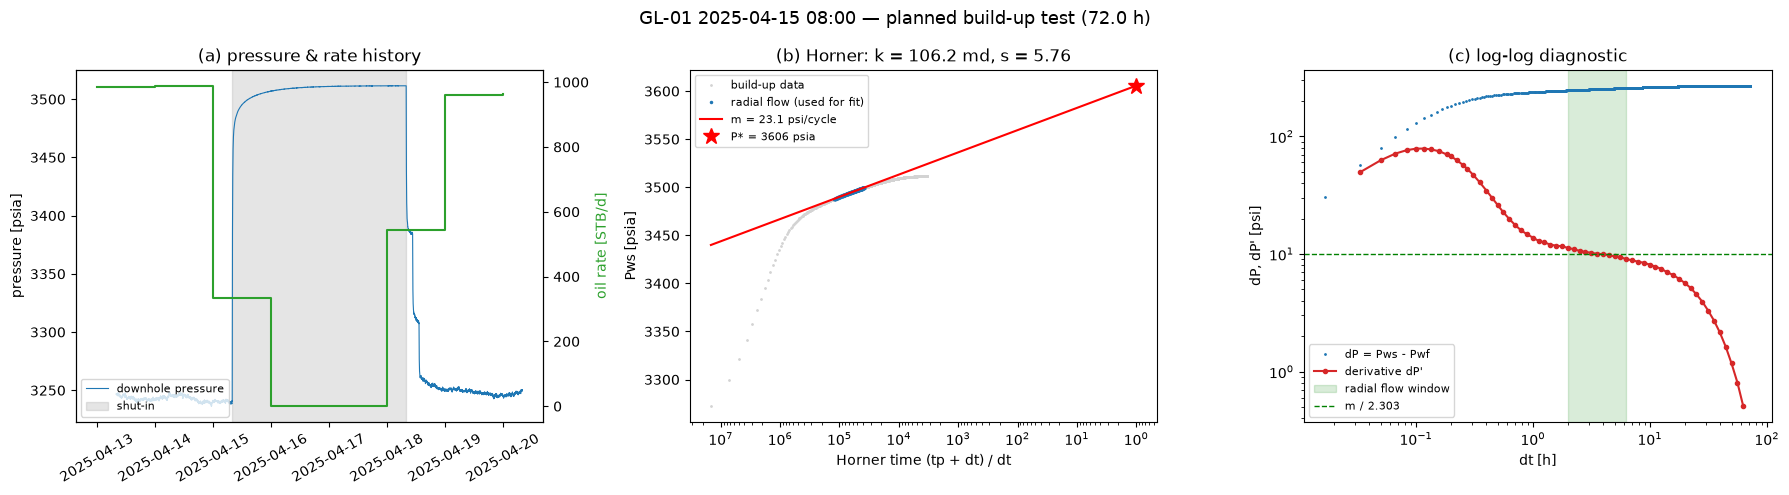

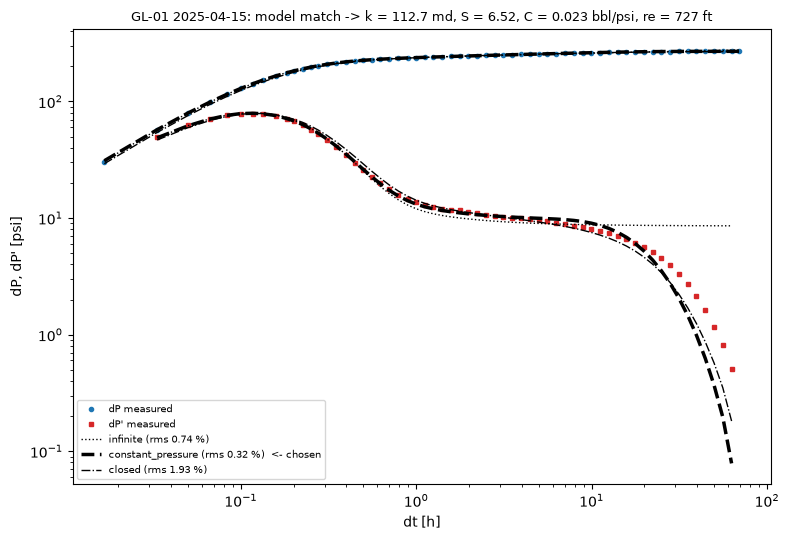

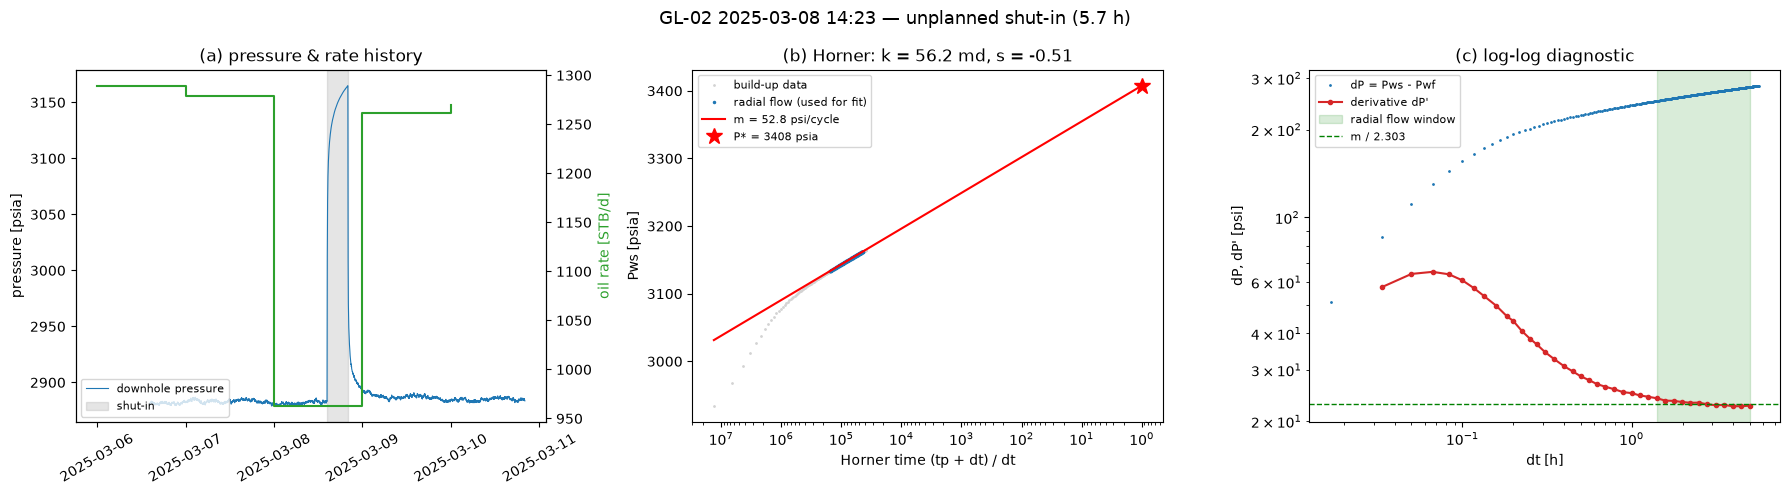

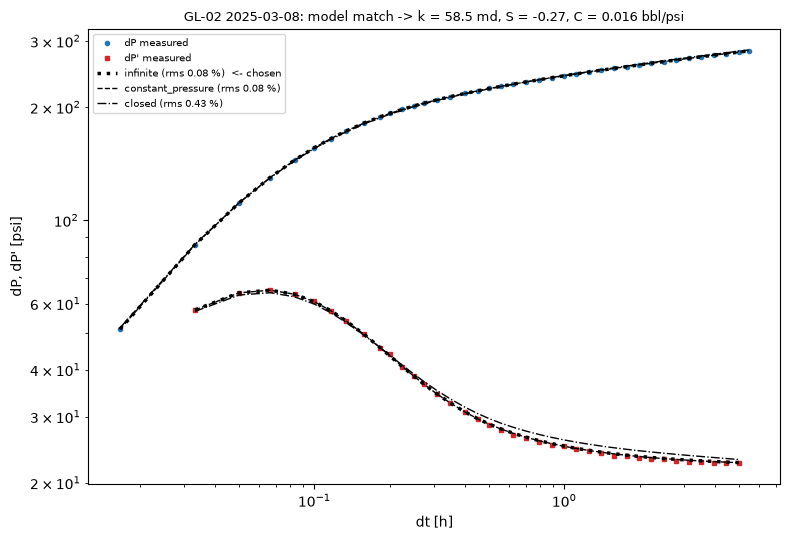

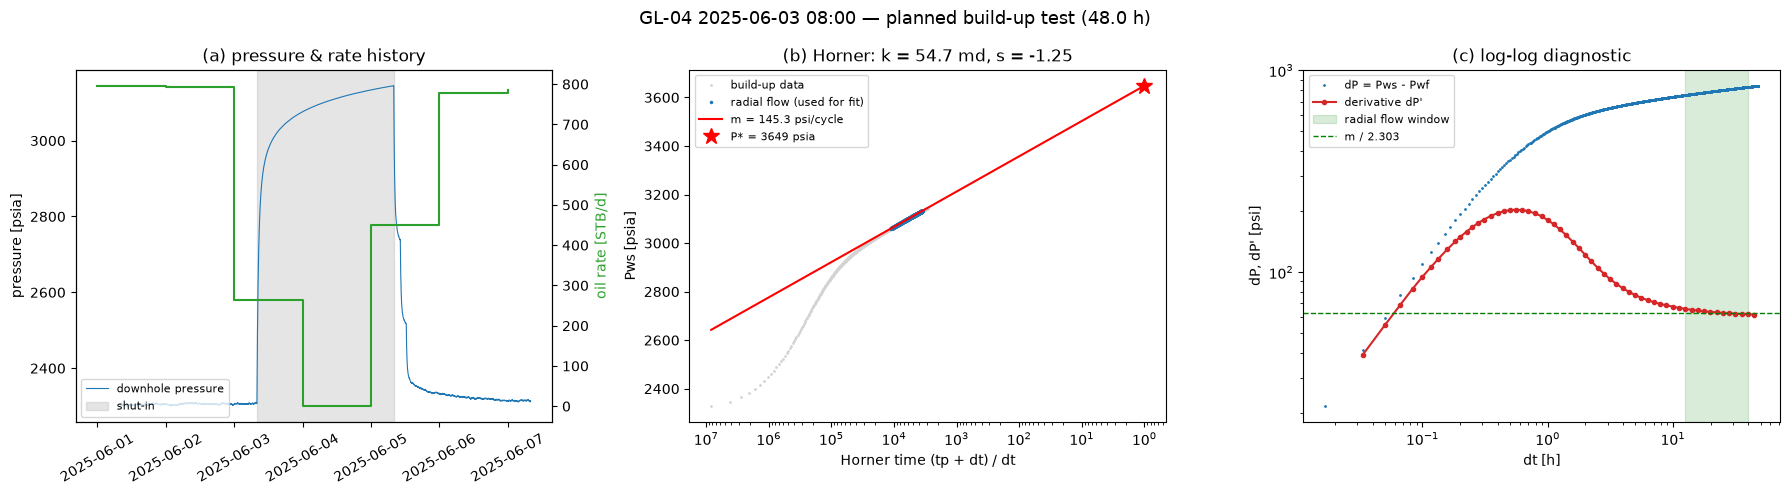

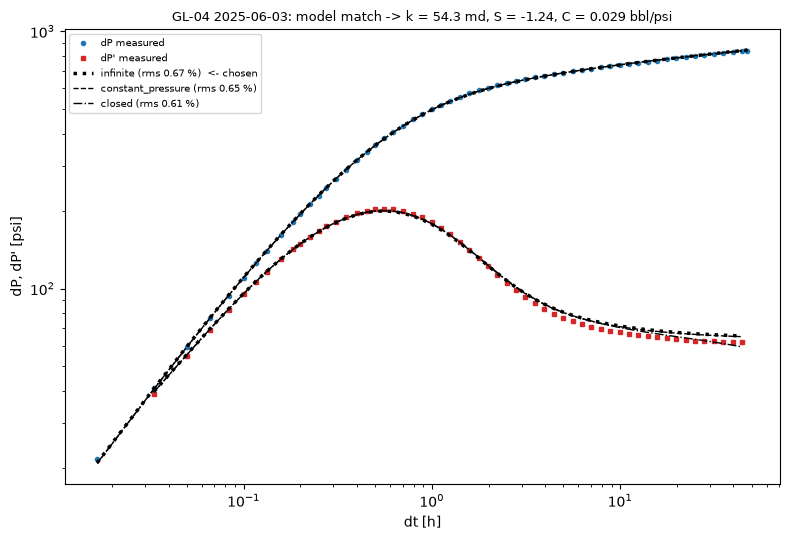

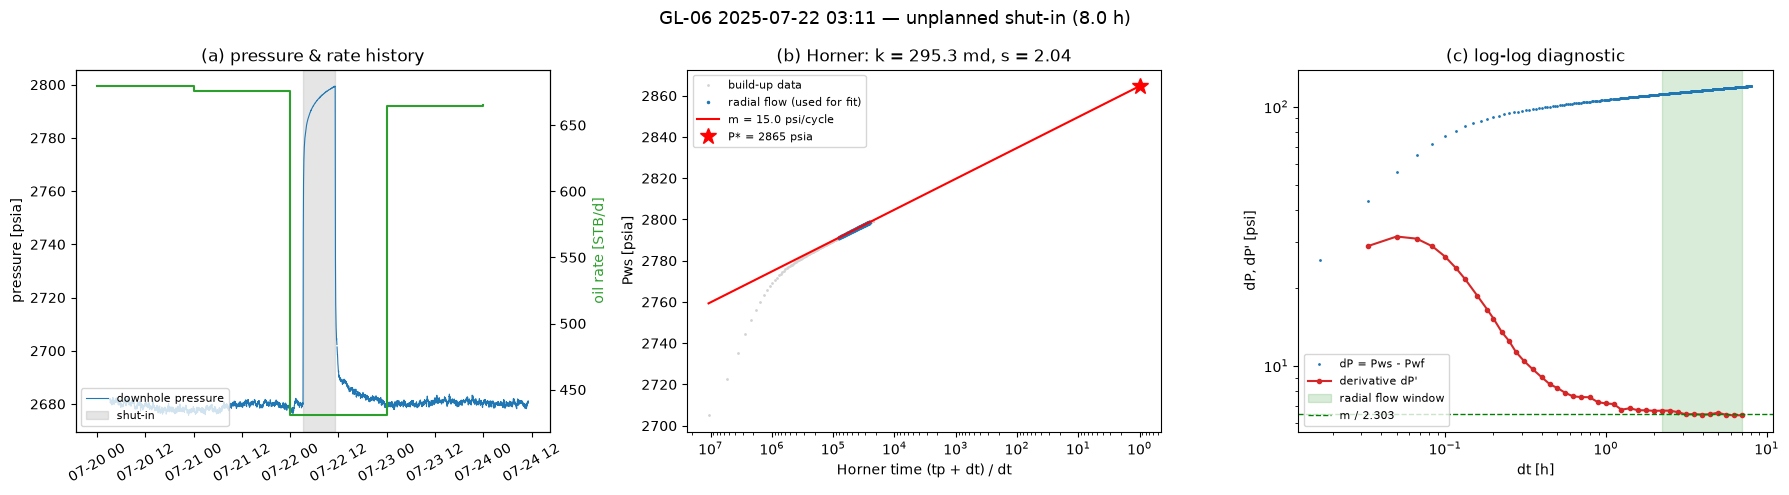

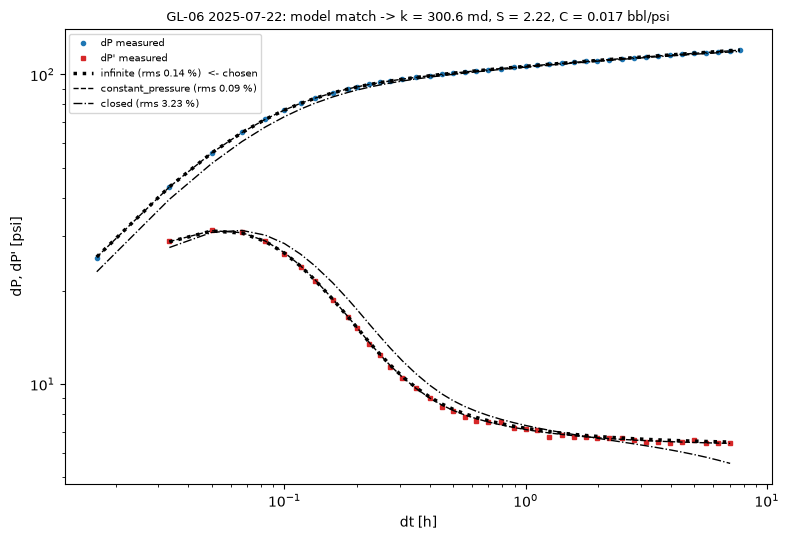

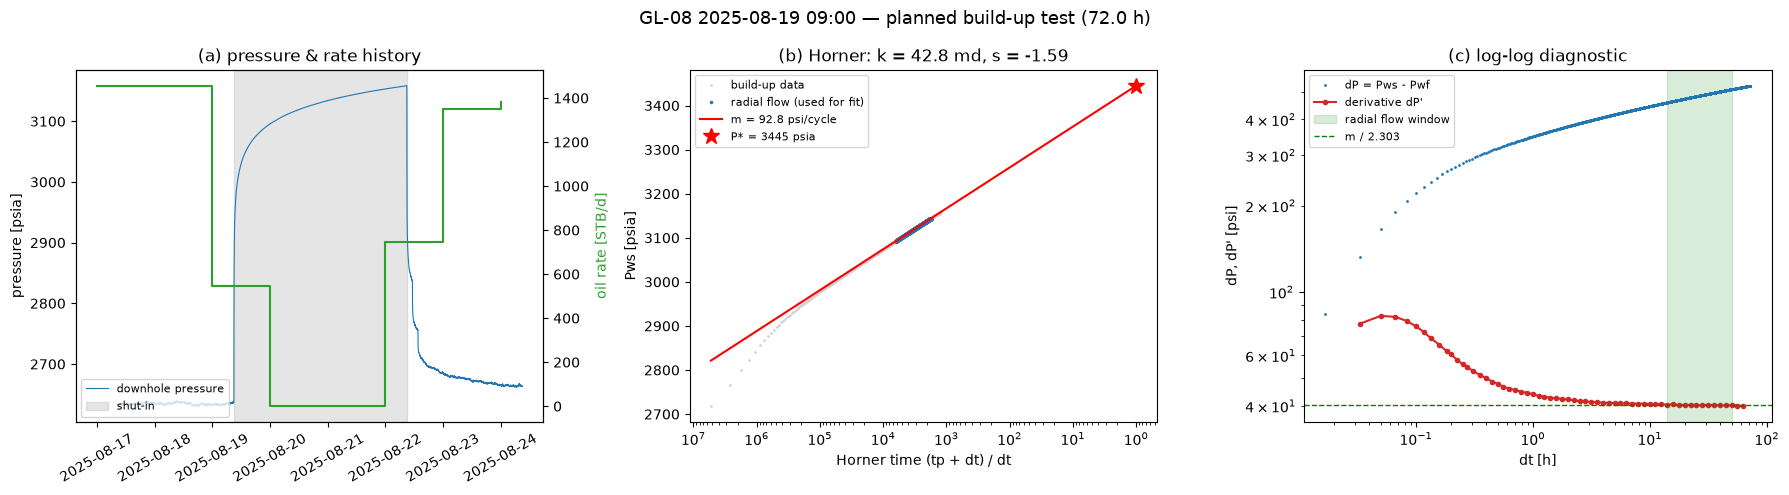

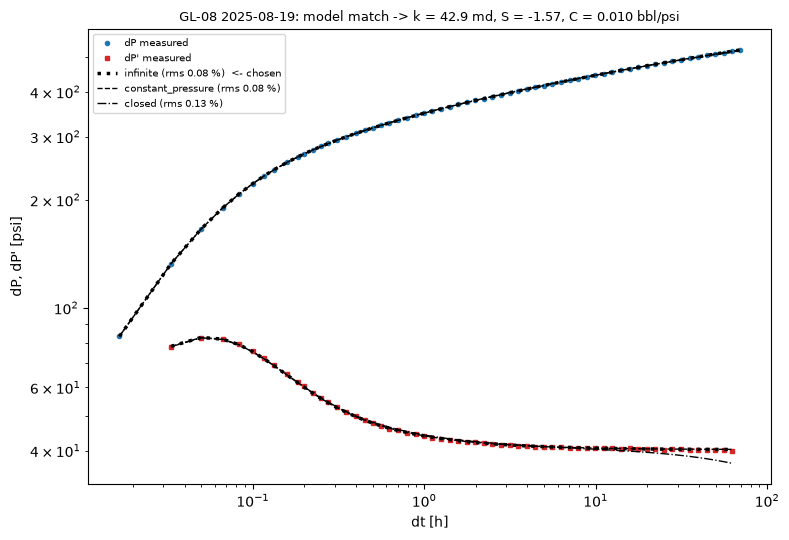

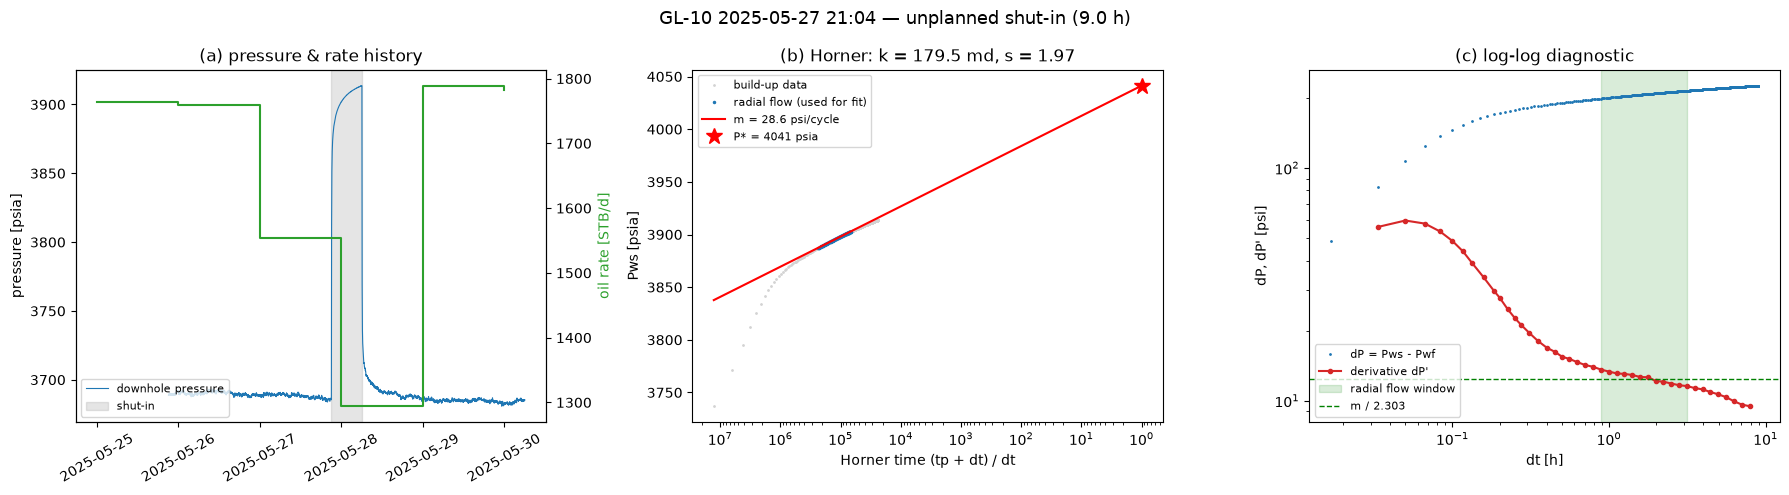

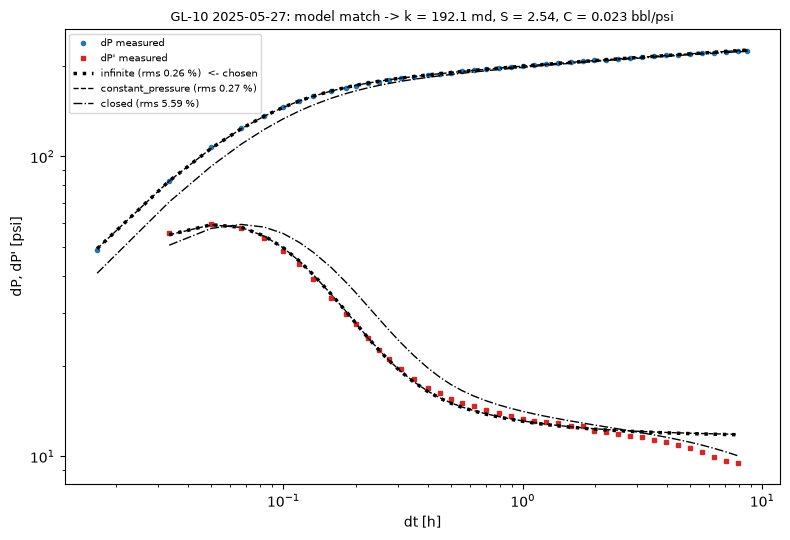

['GL-01_20250415_buildup.png',
 'GL-01_20250415_model_match.png',
 'GL-04_20250603_buildup.png',
 'GL-04_20250603_model_match.png',
 'GL-08_20250819_buildup.png',
 'GL-08_20250819_model_match.png',
 'unplanned_shut_ins\\GL-02_20250308_buildup.png',
 'unplanned_shut_ins\\GL-02_20250308_model_match.png',
 'unplanned_shut_ins\\GL-06_20250722_buildup.png',
 'unplanned_shut_ins\\GL-06_20250722_model_match.png',
 'unplanned_shut_ins\\GL-10_20250527_buildup.png',
 'unplanned_shut_ins\\GL-10_20250527_model_match.png']

In [23]:
plot_dir = OUT / 'pta_plots'
(plot_dir / 'unplanned_shut_ins').mkdir(parents=True, exist_ok=True)
for r in results:
    folder = plot_dir if r['event_type'] == 'planned build-up test' else plot_dir / 'unplanned_shut_ins'
    name = f"{r['well_name']}_{r['t_shut']:%Y%m%d}"
    fig = pta.plot_event(hf, r, vfm_daily)
    fig.suptitle(f"{r['well_name']} {r['t_shut']:%Y-%m-%d %H:%M} — {r['event_type']} ({r['duration_hr']:.1f} h)", fontsize=13)
    fig.savefig(folder / f'{name}_buildup.png', dpi=120)
    plt.show()
    fits, best_fit, dt_fit, dp_fit = fits_all[(r['well_name'], r['t_shut'])]
    fig = pta_model.plot_model_match(r, fits, best_fit, dt_fit, dp_fit)
    fig.savefig(folder / f'{name}_model_match.png', dpi=120)
    plt.show()
sorted(str(p.relative_to(plot_dir)) for p in plot_dir.rglob('*.png'))

## 9. PTA validation

### 9.1 Synthetic benchmark with known truth
There is no "true k" for real data, so we built a simulator (`src/pta_synthetic.py`): our analytical reservoir
model + the **real** PVT, the **real** VFM rate history before each shut-in and 0.3 psi gauge noise, for
6 events × 30 random reservoirs (k, skin, storage, boundary) = 180 synthetic build-ups with known answers. Each
candidate method was scored on them (`src/run_pta_benchmark.py`).

In [24]:
bench = pd.read_csv(OUT / 'pta_benchmark_results.csv')
summary = bench.groupby('method').agg(
    n=('k_err_pct', 'size'),
    k_abs_err_pct_median=('k_err_pct', lambda x: x.abs().median()),
    k_bias_pct_median=('k_err_pct', 'median'),
    skin_abs_err_median=('skin_err', lambda x: x.abs().median()),
    dP_skin_abs_err_psi_median=('dps_err_psi', lambda x: x.abs().median()),
    m_abs_err_pct_median=('m_err_pct', lambda x: x.abs().median()),
).sort_values('k_abs_err_pct_median')
summary.round(3)

,n,k_abs_err_pct_median,k_bias_pct_median,skin_abs_err_median,dP_skin_abs_err_psi_median,m_abs_err_pct_median
method,,,,,,
Model match (best AIC),180,1.214,-0.651,0.087,1.647,1.214
Model match (infinite),180,1.220,-0.651,0.097,2.108,1.230
Horner hourly data (F),180,2.636,-2.277,0.252,6.387,2.708
Horner P1hr measured (E),180,2.801,-2.683,0.428,9.412,2.881
Horner auto (v5),180,2.801,-2.683,0.262,7.391,2.881
Superposition Horner,180,2.881,-2.813,0.252,6.975,2.967
Horner tp since 2025 (C),180,3.268,-3.144,0.295,7.957,3.378
Horner window 1h-end (D),180,5.105,-3.579,0.427,13.140,5.313


Automatic Horner recovers k within a few % and skin within a few tenths; full model matching is more accurate
still and is shown as the cross-check (and gives boundaries and storage).

### 9.2 Consistency between PTA and VFM (independent evidence)
At the end of a long build-up the shut-in pressure approaches the reservoir pressure. The VFM estimates $P_{res}(t)$
**only from the well tests** — so comparing the two is an independent check of the VFM's reservoir-pressure trend.
(For infinite-acting wells the last shut-in pressure is still rising → a lower bound.)

In [25]:
rows = []
for r in results:
    w = hf[(hf.well_name == r['well_name']) & hf.timestamp.between(r['t_open'] - pd.Timedelta(minutes=30), r['t_open'])]
    day = daily.index[(daily.well_name == r['well_name']) & (daily.date == r['t_shut'].normalize() - pd.Timedelta(days=1))]
    p_res = phys_daily.loc[day, 'P_res'].iloc[0]
    rows.append({'well_name': r['well_name'], 'shut_in': r['t_shut'], 'duration_hr': r['duration_hr'],
                 'event_type': r['event_type'], 'last_shut_in_pressure_psia': w.dh_pressure_psia.mean(),
                 'VFM_P_res_trend_psia': p_res})
check = pd.DataFrame(rows)
check['difference_psi'] = check.last_shut_in_pressure_psia - check.VFM_P_res_trend_psia
check.round(1)

,well_name,shut_in,duration_hr,event_type,last_shut_in_pressure_psia,VFM_P_res_trend_psia,difference_psi
0,GL-01,2025-04-15 08:00:00,72.0,planned build-up test,3511.5,3510.3,1.2
1,GL-02,2025-03-08 14:23:00,5.6,unplanned shut-in,3163.9,3219.8,-55.9
2,GL-04,2025-06-03 08:00:00,48.0,planned build-up test,3144.5,3223.9,-79.4
3,GL-06,2025-07-22 03:11:00,8.0,unplanned shut-in,2799.2,2803.2,-3.9
4,GL-08,2025-08-19 09:00:00,72.0,planned build-up test,3158.4,3197.1,-38.8
5,GL-10,2025-05-27 21:04:00,9.0,unplanned shut-in,3913.4,3927.0,-13.6


## 10. The app pipeline on new data — dress rehearsal

The judges run our app on **new raw files** (probably October–December 2025). `src/pipeline.py` (the app's backend)
accepts any subset of the raw files, recognises them by their columns, cleans, predicts with the stored
`models/vfm_model.pkl` (no retraining), carries the cumulative oil and choke history over from the provided
period, detects and classifies shut-ins and runs the PTA.

Rehearsal: give it **only August–September sensor data + choke events** (renamed files, no PVT / completion /
tests) and check that it reproduces the GL-08 build-up test exactly.

In [26]:
with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    hf_raw[hf_raw.timestamp >= '2025-08-01'].to_csv(tmp / 'sensors_new_period.csv', index=False)
    choke[choke.timestamp >= '2025-08-01'].to_csv(tmp / 'chokes.csv', index=False)
    summary = pipeline.run([tmp / 'sensors_new_period.csv', tmp / 'chokes.csv'], tmp / 'bundle',
                           progress=lambda step, msg: print(f'[{step}] {msg}'))
    rehearsal = pd.read_excel(tmp / 'bundle' / 'PTA_results.xlsx', sheet_name='pta_results')
print('\nperiod:', summary['period'], '| warnings:', summary['warnings'])
rehearsal

[validate] Checking the uploaded files


[clean] Cleaning sensor data (null codes, duplicates, spikes) and marking shut-ins


[features] Building daily features (physics features, on-stream fraction)


[vfm] Predicting daily oil, water and gas with the stored VFM model
[pta] Detecting shut-ins, classifying them and running the build-up analysis


[export] Writing Excel results


[done] Finished

period: {'start': '2025-08-01 00:00:00', 'end': '2025-09-30 23:59:00'} | warnings: ['No pvt file uploaded -> using the bundled one', 'No completion file uploaded -> using the bundled one']


,well_name,shut_in_start,shut_in_duration_hr,horner_slope_m_psi_per_cycle,skin,permeability_md,delta_p_skin_psi
0,GL-08,2025-08-19 09:00:00,72,92.77,-1.59,42.76,-127.99


## 11. Summary of the final results

In [27]:
print('VFM — official metrics (%, R2) of the final model')
print(final_metrics.to_string())
print('\nPTA — planned build-up tests')
print(pta_results_table.to_string(index=False))
print('\nDeliverable files:')
for p in ['outputs/VFM_predictions.xlsx', 'outputs/VFM_predictions.csv', 'models/vfm_model.pkl',
          'outputs/PTA_results.xlsx', 'outputs/PTA_results.csv', 'outputs/final_model_metrics.json']:
    f = load.ROOT / p
    print(f'  {p:40s} {f.stat().st_size / 1e3:9.1f} kB')
print(f"  outputs/plots/                           {len(list((OUT / 'plots').glob('vfm_*.png')))} VFM plots")
print(f"  outputs/pta_plots/                       {len(list((OUT / 'pta_plots').rglob('*.png')))} PTA plots")
print(f'\nnotebook runtime: {(time.time() - T0) / 60:.1f} min')

VFM — official metrics (%, R2) of the final model
                     R2   MAPE   WAPE
validation fluid                     
loto       oil    0.999  2.392  2.029
           water  0.997  3.424  3.081
           gas    0.995  5.498  4.328
forward    oil    0.996  4.279  3.521
           water  0.988  4.547  4.917
           gas    0.993  8.034  5.630

PTA — planned build-up tests
well_name       shut_in_start  shut_in_duration_hr  horner_slope_m_psi_per_cycle  skin  permeability_md  delta_p_skin_psi
    GL-01 2025-04-15 08:00:00                 72.0                         23.12  5.76           106.21            115.64
    GL-04 2025-06-03 08:00:00                 48.0                        145.34 -1.25            54.72           -158.29
    GL-08 2025-08-19 09:00:00                 72.0                         92.77 -1.59            42.76           -127.99

Deliverable files:
  outputs/VFM_predictions.xlsx                 187.7 kB
  outputs/VFM_predictions.csv                  105.2

**Take-aways**
* **VFM:** a physics-first model — Darcy inflow with our own build-up permeability & skin, a local reservoir-pressure
  trend, gas from the solution GOR, and a Gaussian process only where it adds information (water) and only on
  inputs that are not distorted by the test separator. Between tests: WAPE ≈ 2 % oil, 3 % water, 4 % gas;
  forecasting 0–3 months: ≈ 3.5 % / 5 % / 5.6 %.
* **PTA:** fully automatic — shut-in detection, textbook classification of planned build-up tests, derivative-based
  radial-flow window, Horner k / skin / ΔP skin, analytical model match (boundaries, storage), sensitivity, plots.
* **Validated** with leave-one-test-out, time-forward forecasting, a normal-day bias check, a synthetic PTA
  benchmark with known truth, and the independent PTA ↔ VFM reservoir-pressure consistency.
* **Ready for new data:** the same pipeline runs inside the WellMind app on any uploaded subset of raw files.